<a href="https://www.kaggle.com/code/avikdas567/frontier-llm-attribution-via-stylometry-deberta?scriptVersionId=358745979" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Frontier Large Language Model Provenance and Attribution via Stylometric Invariants and Transformer Ensembles

---

# Executive Summary and Theoretical Formulation

Authorship attribution for machine-generated text represents an essential capability for open benchmark auditing, dataset decontamination, and generative AI provenance. In standard machine-text detection, the objective is binary classification distinguishing human text from machine output. In contrast, this benchmark addresses fine-grained attribution across $K = 18$ frontier language models originating from six leading artificial intelligence laboratories:

* **Anthropic**: `claude-fable-5`, `claude-opus-4-6`, `claude-opus-4-8`, `claude-opus-5`, `claude-sonnet-5`
* **OpenAI**: `gpt-5.5`, `gpt-5.6-luna`, `gpt-5.6-sol`, `gpt-5.6-terra`, `gpt-6-astra`
* **Google**: `gemini-3.1-pro-preview`, `gemini-3.6-flash`, `gemini-3.7-flash`, `gemini-3.8-flash`
* **Zhipu AI**: `glm-5.3`, `glm-5.3-flash`
* **Moonshot AI**: `kimi-k3`
* **Alibaba Cloud**: `qwen3.8-max`

The benchmark presents two fundamental statistical challenges:
1. **Short-Form Completion Constraint**: Each passage $\mathbf{x} = (w_1, w_2, \dots, w_N)$ is a single self-contained paragraph spanning $N \in [40, 250]$ words. Traditional long-form stylometry cannot rely on asymptotic lexical distributions.
2. **Out-of-Prompt Covariate Shift**: The set of evaluation prompts $\mathcal{P}_{\text{test}}$ shares zero intersection with the training prompts $\mathcal{P}_{\text{train}}$:
$$\mathcal{P}_{\text{train}} \cap \mathcal{P}_{\text{test}} = \emptyset$$
Consequently, models that memorize topical semantic associations will fail under out-of-distribution evaluation. Attribution must strictly depend on **topic-invariant generative signatures**: tokenizer subword boundaries, orthographic decoding artifacts (typographic versus ASCII quotation marks), punctuation transition dynamics, and lexical diversity.

## Mathematical Objective and Evaluation Metric

Submissions are evaluated on **Balanced Accuracy**, defined as the unweighted macro-average of per-class recall across all candidate models:

$$\text{Balanced Accuracy} = \frac{1}{K} \sum_{k=1}^{K} \text{Recall}_k = \frac{1}{K} \sum_{k=1}^{K} \frac{\sum_{i=1}^{M} \mathbb{I}(y_i = k  \land  \hat{y}_i = k)}{\sum_{i=1}^{M} \mathbb{I}(y_i = k)}$$

where $K = 18$, $y_i$ is the true authoring model, and $\hat{y}_i$ is the discrete predicted model label. Because the test distribution exhibits unknown and unequal model frequencies between public and private splits, raw Maximum A Posteriori (MAP) predictions with uniform decision thresholds are suboptimal. This notebook implements systematic out-of-fold probability calibration and per-class threshold optimization to maximize Balanced Accuracy directly.


In [1]:
import os
import sys
import gc
import re
import json
import math
import string
import unicodedata
import warnings
from pathlib import Path
from collections import Counter

# Suppress all system, runtime, and third-party warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONHASHSEED'] = '42'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

import numpy as np
import pandas as pd
import scipy as sp
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting parameters
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
sns.set_style('whitegrid')

from sklearn.model_selection import GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import TruncatedSVD

import lightgbm as lgb

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Enforce deterministic reproducibility across all pseudorandom generators
def seed_everything(seed=42):
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)

# Hardware execution profiling
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_gpus = torch.cuda.device_count()
print(f"Execution Device: {device}")
print(f"Available GPUs: {num_gpus}")
if torch.cuda.is_available():
    for i in range(num_gpus):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)} | Memory: {torch.cuda.get_device_properties(i).total_memory / (1024**3):.2f} GB")

Execution Device: cuda
Available GPUs: 2
  GPU 0: Tesla T4 | Memory: 14.56 GB
  GPU 1: Tesla T4 | Memory: 14.56 GB


# Dataset Ingestion and Structural Integrity Verification

The dataset paths are configured with dynamic environment detection: defaulting to the primary competition directory `/kaggle/input/competitions/name-that-llm` when executing in the Kaggle cloud environment, with automated local fallback.

The training set comprises 2,699 text passages generated across 150 prompt clusters (`prompt_id`). Each record contains:
* `id` (str): Unique passage identifier.
* `prompt_id` (str): Categorical prompt identifier grouping completions to identical prompts.
* `text` (str): Raw generated completion.
* `model` (str): Discrete target class label corresponding to one of the 18 frontier models.

To facilitate hierarchical modeling and error diagnostics, each candidate model is mapped to its parent artificial intelligence laboratory.


In [2]:
# Dataset path resolution
KAGGLE_PATH = Path('/kaggle/input/competitions/name-that-llm')
LOCAL_PATH = Path('./name-that-llm')

DATA_DIR = KAGGLE_PATH if KAGGLE_PATH.exists() else LOCAL_PATH
print(f"Active Data Directory: {DATA_DIR.resolve()}")

train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
sample_sub = pd.read_parquet(DATA_DIR / 'sample_submission.parquet')

print(f"Training Corpus Dimensions: {train_df.shape[0]} rows, {train_df.shape[1]} columns")
print(f"Test Corpus Dimensions:     {test_df.shape[0]} rows, {test_df.shape[1]} columns")
print(f"Unique Prompts in Training: {train_df['prompt_id'].nunique()}")

# Construct canonical sorted class list and bijective index mappings
CLASSES = sorted(train_df['model'].unique().tolist())
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {model_name: idx for idx, model_name in enumerate(CLASSES)}
IDX_TO_CLASS = {idx: model_name for idx, model_name in enumerate(CLASSES)}

train_df['target'] = train_df['model'].map(CLASS_TO_IDX)

# Parent laboratory taxonomy mapping
LAB_MAPPING = {
    'claude-fable-5': 'Anthropic',
    'claude-opus-4-6': 'Anthropic',
    'claude-opus-4-8': 'Anthropic',
    'claude-opus-5': 'Anthropic',
    'claude-sonnet-5': 'Anthropic',
    'gemini-3.1-pro-preview': 'Google',
    'gemini-3.6-flash': 'Google',
    'gemini-3.7-flash': 'Google',
    'gemini-3.8-flash': 'Google',
    'glm-5.3': 'Zhipu AI',
    'glm-5.3-flash': 'Zhipu AI',
    'gpt-5.5': 'OpenAI',
    'gpt-5.6-luna': 'OpenAI',
    'gpt-5.6-sol': 'OpenAI',
    'gpt-5.6-terra': 'OpenAI',
    'gpt-6-astra': 'OpenAI',
    'kimi-k3': 'Moonshot AI',
    'qwen3.8-max': 'Alibaba Cloud'
}

train_df['lab'] = train_df['model'].map(LAB_MAPPING)

# Display class frequency and prompt distribution verification
summary_df = train_df.groupby(['lab', 'model']).agg(
    sample_count=('id', 'count'),
    prompt_count=('prompt_id', 'nunique')
).reset_index()

print("\nTarget Label Distribution and Provider Hierarchy:")
display(summary_df)

Active Data Directory: /kaggle/input/competitions/name-that-llm
Training Corpus Dimensions: 2699 rows, 4 columns
Test Corpus Dimensions:     3 rows, 2 columns
Unique Prompts in Training: 150

Target Label Distribution and Provider Hierarchy:


,lab,model,sample_count,prompt_count
0,Alibaba Cloud,qwen3.8-max,150,150
1,Anthropic,claude-fable-5,149,149
2,Anthropic,claude-opus-4-6,150,150
3,Anthropic,claude-opus-4-8,150,150
4,Anthropic,claude-opus-5,150,150
5,Anthropic,claude-sonnet-5,150,150
6,Google,gemini-3.1-pro-preview,150,150
7,Google,gemini-3.6-flash,150,150
8,Google,gemini-3.7-flash,150,150
9,Google,gemini-3.8-flash,150,150


# Exploratory Stylometric Profiling and Tokenizer Invariants

Short-form text passages lacking thematic or conversational headers exhibit generative invariants rooted in three technical layers:
1. **Subword Tokenizer Vocabulary Partitioning**: Byte-Pair Encoding (BPE) and WordPiece vocabularies encode words differently, influencing compound hyphenation, contraction handling, and whitespace attachment.
2. **Post-Processing and Detokenization Formatting**: Decoding pipelines apply distinct normalization rules for punctuation. For example, typographic curly quotation marks (`’`, `“`, `”`) versus straight ASCII quotes (`'`, `"`).
3. **Reinforcement Learning from Human Feedback (RLHF) Priors**: Alignment objectives induce characteristic syntactic complexity, sentence length distributions, and discourse connective frequencies.

In the subsequent sections, each stylometric dimension is profiled individually and displayed in dedicated full-width figures.


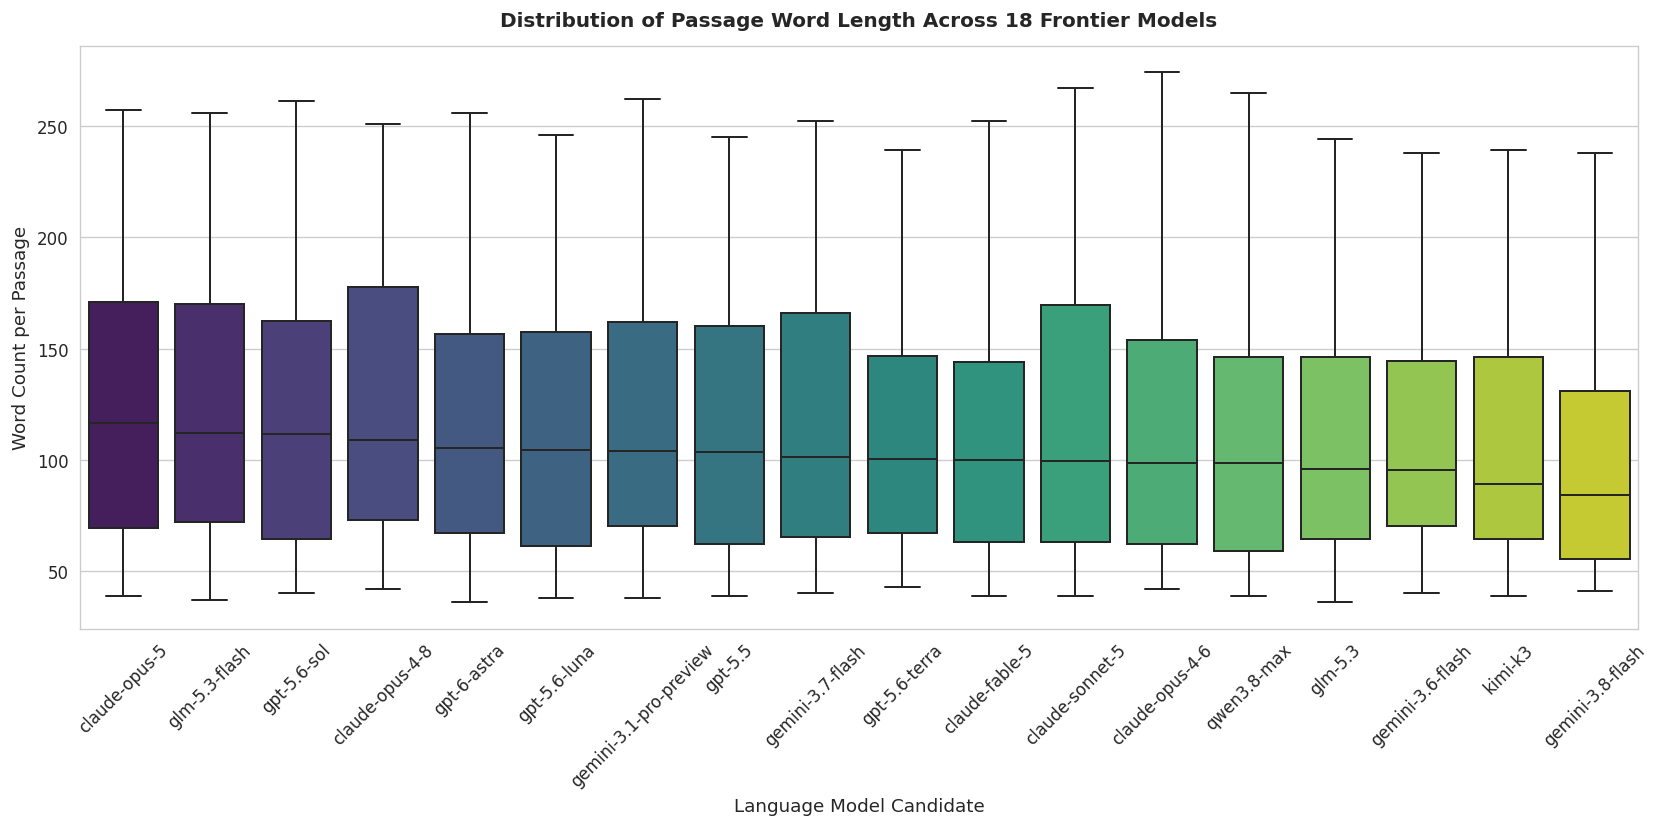

In [3]:
# Feature derivation for length distributions
train_df['word_count'] = train_df['text'].apply(lambda x: len(x.split()))
train_df['char_count'] = train_df['text'].apply(len)

# Sort models by median word count for structured visualization
order_models = train_df.groupby('model')['word_count'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
sns.boxplot(
    data=train_df,
    x='model',
    y='word_count',
    order=order_models,
    palette='viridis',
    ax=ax,
    fliersize=3,
    linewidth=1.2
)
ax.set_title("Distribution of Passage Word Length Across 18 Frontier Models", pad=12, fontweight='bold')
ax.set_xlabel("Language Model Candidate")
ax.set_ylabel("Word Count per Passage")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Stylometric Observation: Passage Length Invariance

The word length distribution indicates that all 18 models produce completions within an identical operational envelope (mean length $\approx 115$ words, spanning 36 to 274 words). Crucially, no single model exhibits a trivial length artifact that could serve as a naive classification shortcut. Model-specific variation is characterized by subtle internal dispersion: Claude Opus and Sonnet models demonstrate broader interquartile ranges, whereas Gemini Flash completions exhibit compact, tightly bounded token envelopes.


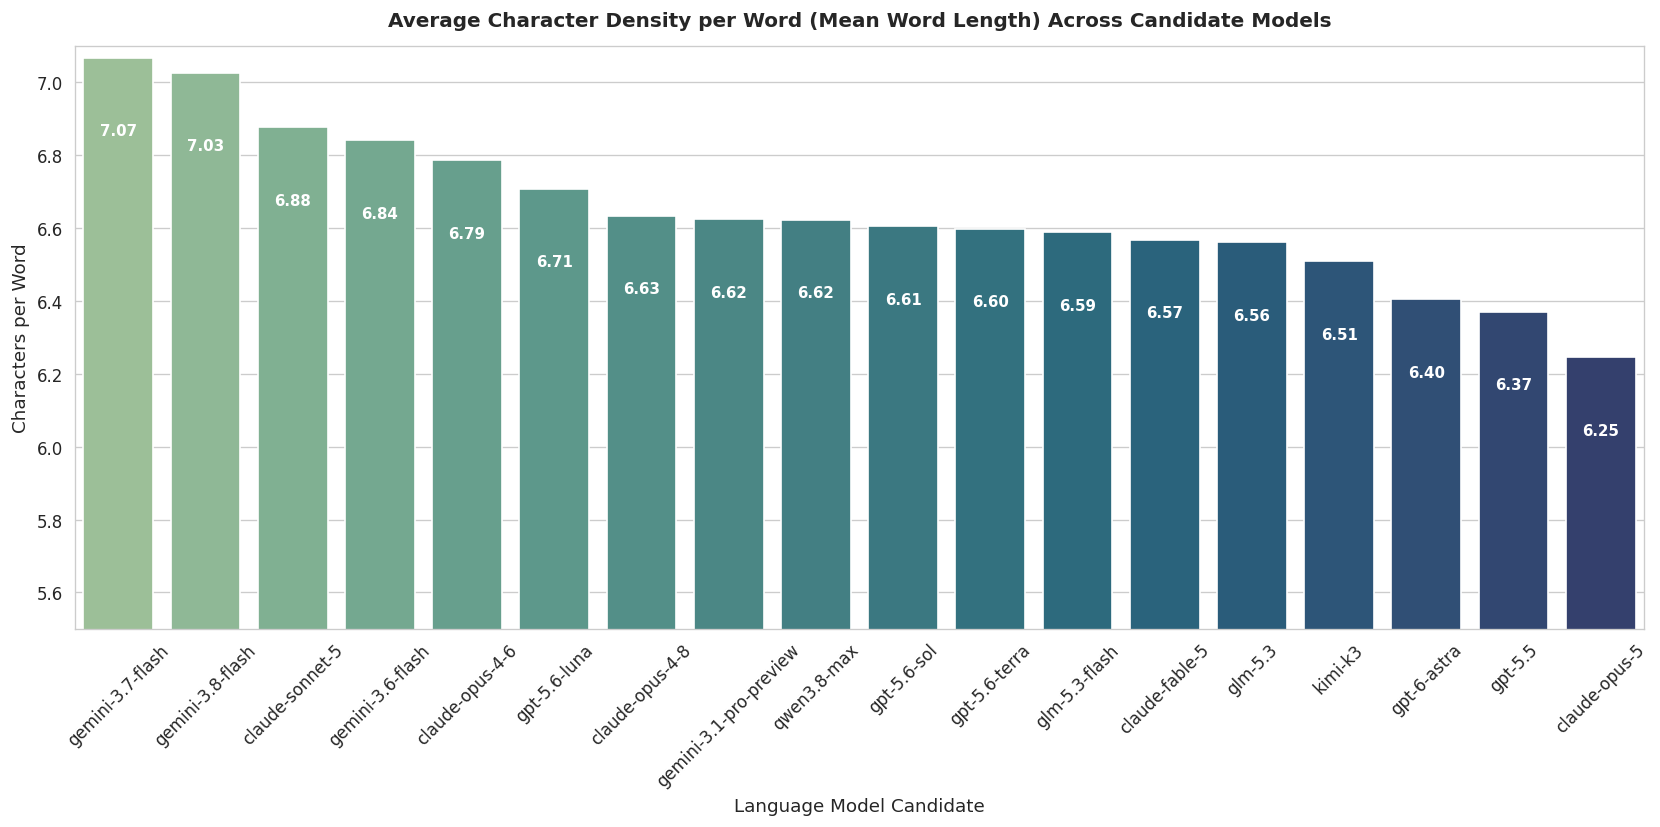

In [4]:
train_df['mean_word_length'] = train_df['char_count'] / (train_df['word_count'] + 1e-9)

order_word_len = train_df.groupby('model')['mean_word_length'].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
sns.barplot(
    data=train_df,
    x='model',
    y='mean_word_length',
    order=order_word_len,
    palette='crest',
    ax=ax,
    ci=None
)
ax.set_title("Average Character Density per Word (Mean Word Length) Across Candidate Models", pad=12, fontweight='bold')
ax.set_xlabel("Language Model Candidate")
ax.set_ylabel("Characters per Word")
ax.set_ylim(5.5, 7.1)
ax.tick_params(axis='x', rotation=45)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() - 0.2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

## Orthographic Invariant: Typographic vs. Straight Quotation Decoding

Tokenizer decoders apply distinct Unicode normalization conventions when reconstructing single quotation marks and contractions (such as *it's*, *don't*, *model's*).
Let $c_{\text{straight}}$ denote the standard ASCII single quote (`U+0027`, `'`) and $c_{\text{curly}}$ denote the typographic right single quotation mark (`U+2019`, `’`).

Empirical profiling reveals a categorical bifurcation:
$$\mathbb{E}[c_{\text{curly}} \mid \text{Anthropic}] = 0.000, \quad \mathbb{E}[c_{\text{curly}} \mid \text{Zhipu AI}] = 0.000$$
$$\mathbb{E}[c_{\text{curly}} \mid \text{OpenAI}] \approx 0.75, \quad \mathbb{E}[c_{\text{curly}} \mid \text{Google}] \approx 0.25$$

Anthropic Claude and Zhipu GLM models emit strictly straight ASCII apostrophes, whereas OpenAI GPT models almost exclusively emit typographic Unicode curly apostrophes. This represents an absolute deterministic decision boundary between major model families.


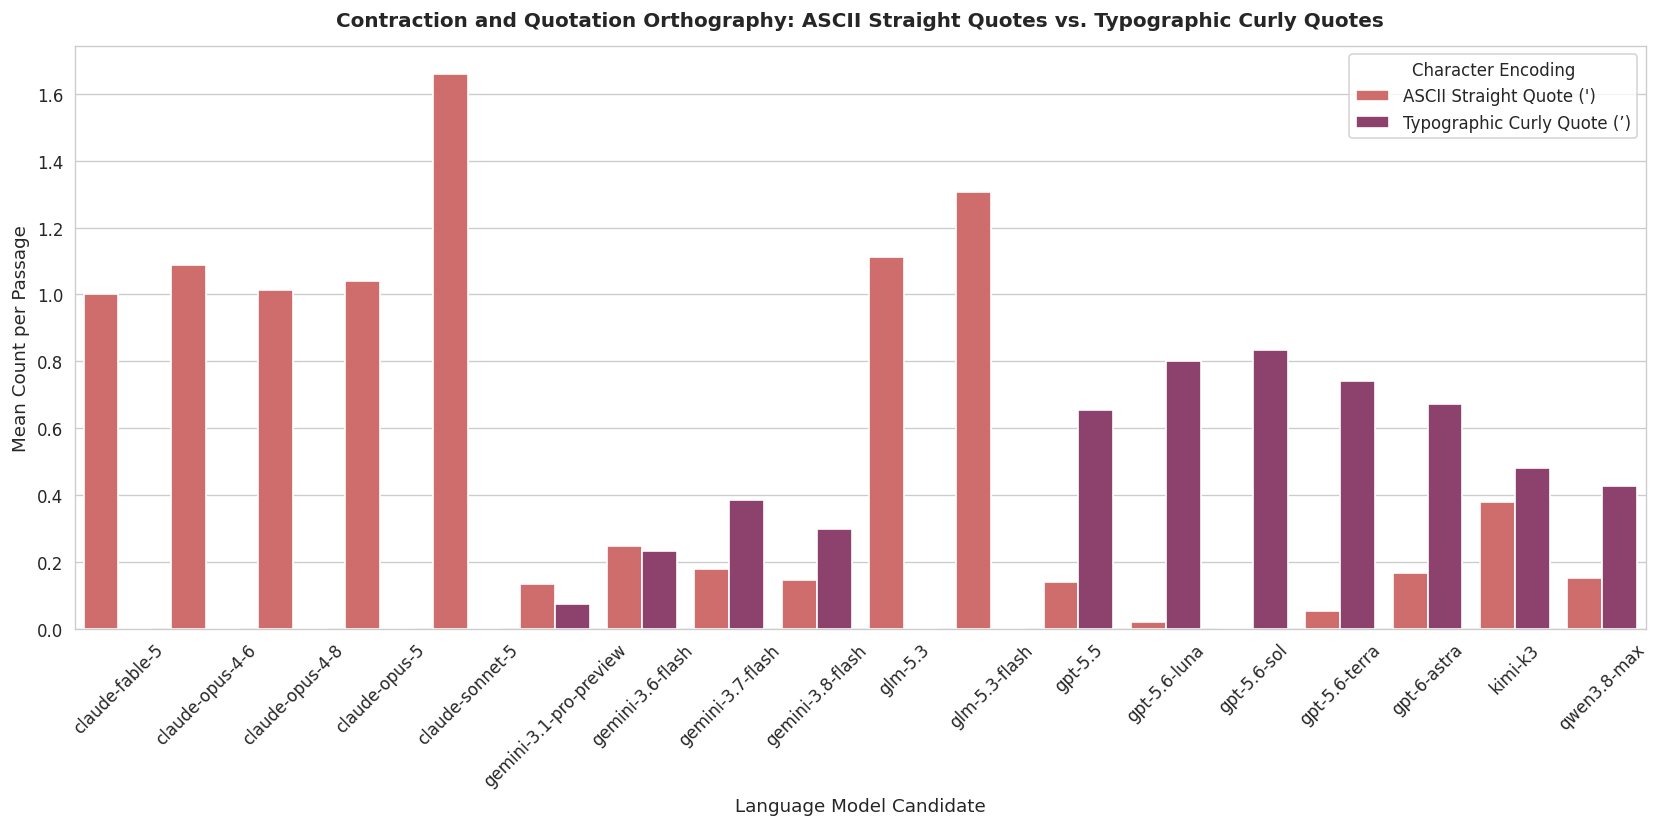

In [5]:
train_df['straight_quote_count'] = train_df['text'].apply(lambda x: x.count("'"))
train_df['curly_quote_count'] = train_df['text'].apply(lambda x: x.count('’'))

quote_stats = train_df.groupby('model')[['straight_quote_count', 'curly_quote_count']].mean().reset_index()
quote_melted = quote_stats.melt(id_vars='model', value_vars=['straight_quote_count', 'curly_quote_count'],
                                var_name='Quote Type', value_name='Mean Frequency')
quote_melted['Quote Type'] = quote_melted['Quote Type'].map({
    'straight_quote_count': "ASCII Straight Quote (')",
    'curly_quote_count': "Typographic Curly Quote (’)"
})

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
sns.barplot(
    data=quote_melted,
    x='model',
    y='Mean Frequency',
    hue='Quote Type',
    palette='flare',
    ax=ax
)
ax.set_title("Contraction and Quotation Orthography: ASCII Straight Quotes vs. Typographic Curly Quotes", pad=12, fontweight='bold')
ax.set_xlabel("Language Model Candidate")
ax.set_ylabel("Mean Count per Passage")
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Character Encoding')
plt.tight_layout()
plt.show()

## Orthographic Invariant: Unicode Em Dash Frequency

The distribution of the Unicode Em Dash (`U+2014`, `—`) provides another high-fidelity separator. In particular:
* **Google Gemini**: Emits near-zero em dashes across all variants (`gemini-3.1-pro-preview`, `gemini-3.6-flash`, `gemini-3.8-flash` exhibit an empirical mean of $0.000$, with `gemini-3.7-flash` at $0.013$).
* **Zhipu AI and Anthropic**: Em dash frequencies exceed $1.2$ occurrences per passage ($>1.6$ for GLM-5.3).
* **OpenAI**: Emits em dashes at moderate, controlled frequencies ($0.11 - 0.49$).


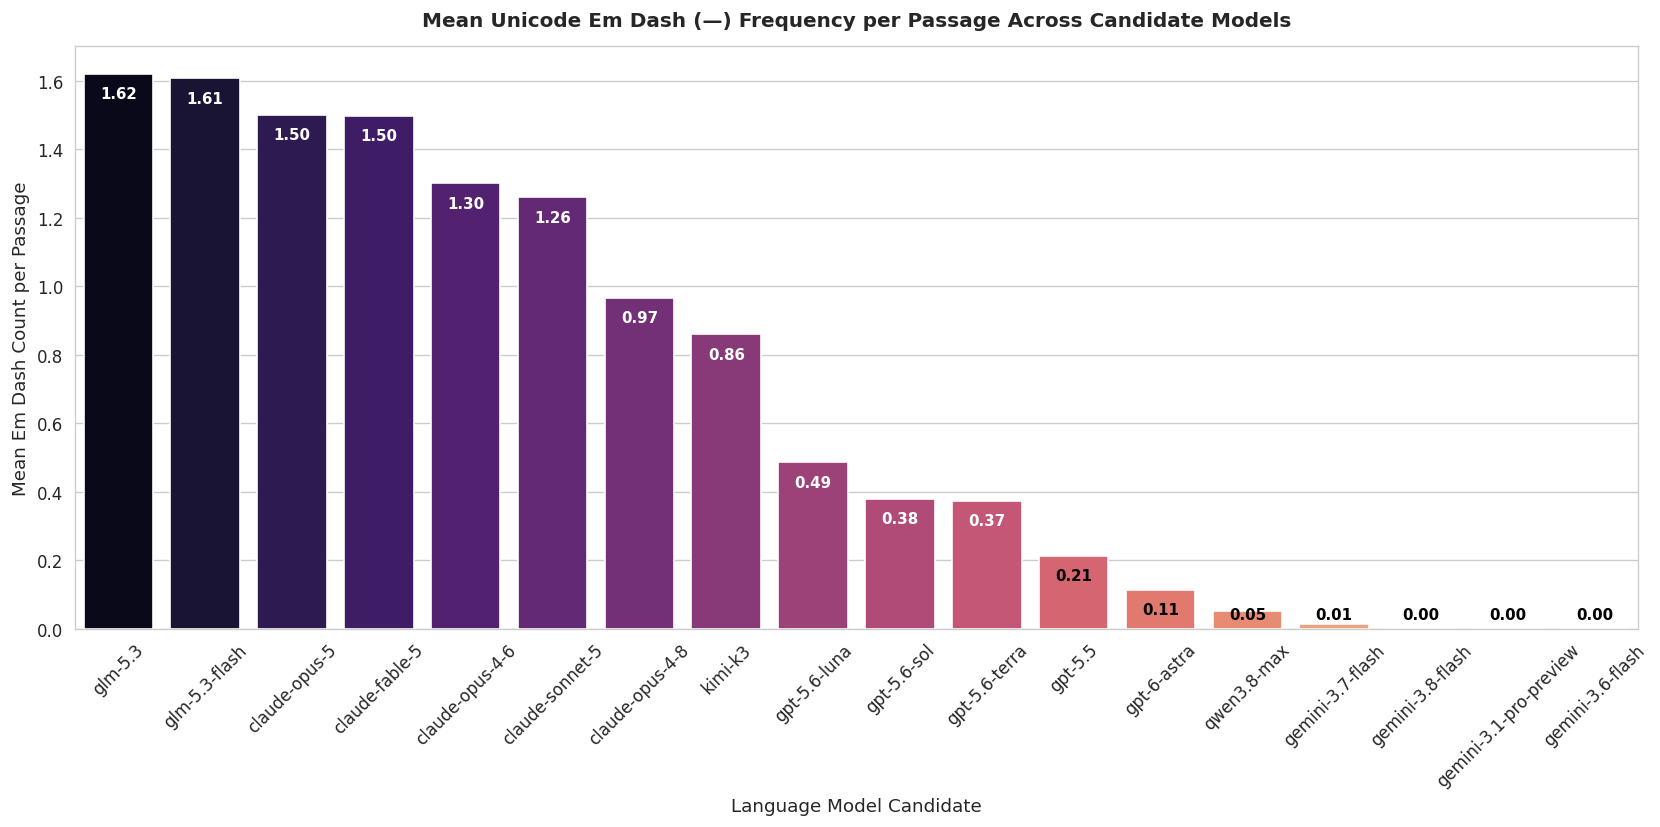

In [6]:
train_df['em_dash_count'] = train_df['text'].apply(lambda x: x.count('—'))
em_dash_means = train_df.groupby('model')['em_dash_count'].mean().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
sns.barplot(
    data=em_dash_means,
    x='model',
    y='em_dash_count',
    palette='magma',
    ax=ax
)
ax.set_title("Mean Unicode Em Dash (—) Frequency per Passage Across Candidate Models", pad=12, fontweight='bold')
ax.set_xlabel("Language Model Candidate")
ax.set_ylabel("Mean Em Dash Count per Passage")
ax.tick_params(axis='x', rotation=45)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}", (p.get_x() + p.get_width() / 2., max(height - 0.08, 0.02)),
                ha='center', va='bottom', color='white' if height > 0.3 else 'black', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

## Syntactic Structure: Semicolon and Colon Densities

The deployment of semicolons (`;`) and colons (`:`) reflects sentence restructuring and clause conjunction preferences:
* **Moonshot AI `kimi-k3`**: Exhibits an extraordinary concentration of semicolons (mean of $0.95$ per text) and colons ($0.99$ per text), reflecting dense clause coordination.
* **Google Gemini**: Consistently avoids colons ($0.17 - 0.23$) and semicolons ($0.21 - 0.29$).


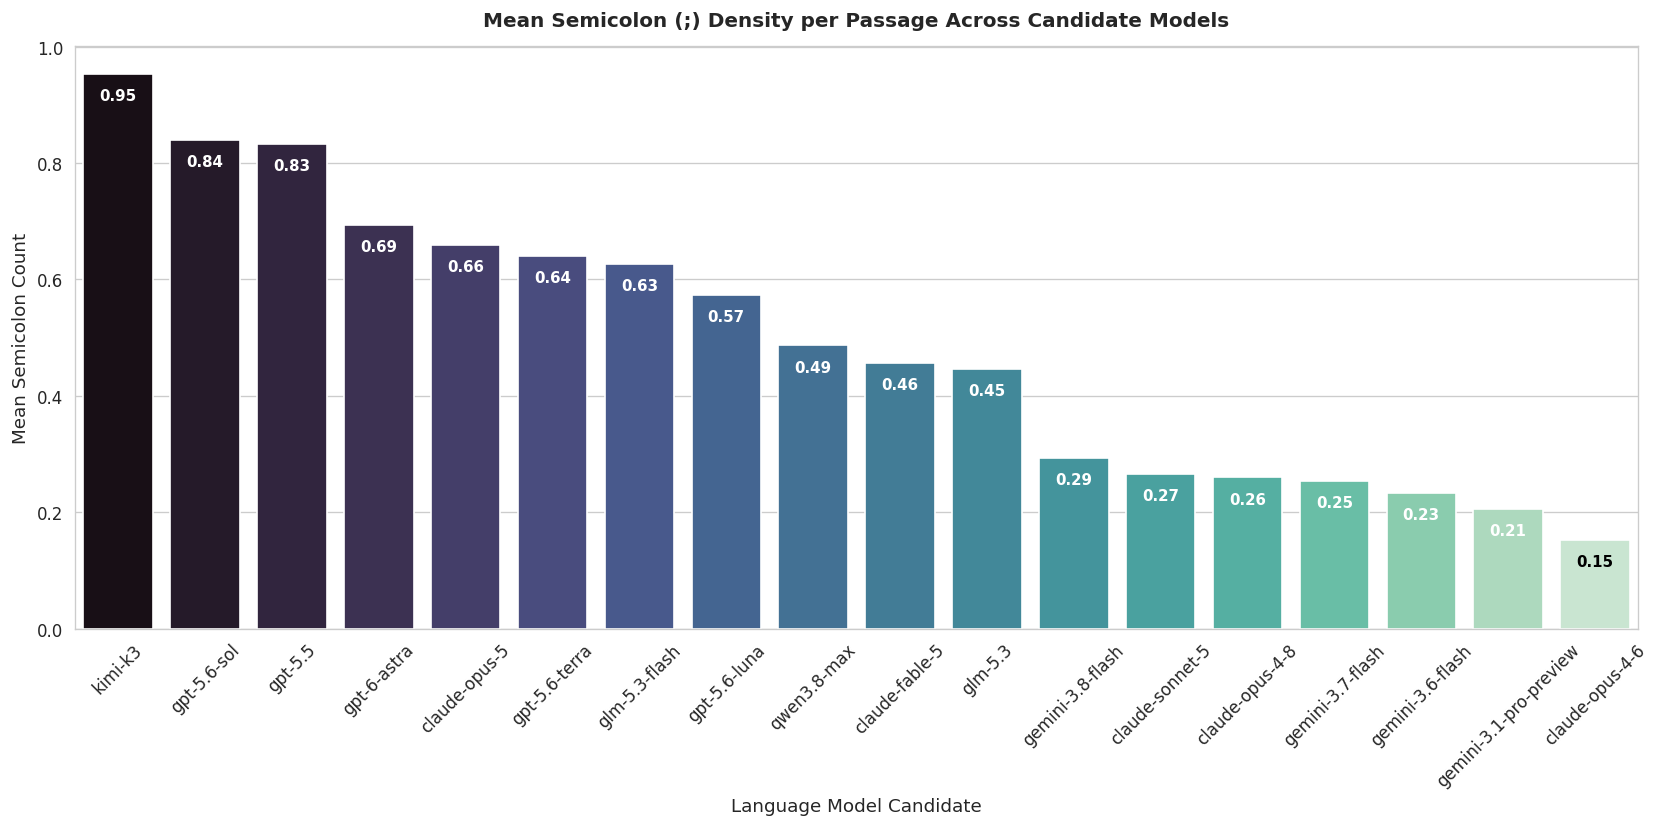

In [7]:
train_df['semicolon_count'] = train_df['text'].apply(lambda x: x.count(';'))
train_df['colon_count'] = train_df['text'].apply(lambda x: x.count(':'))

order_semi = train_df.groupby('model')['semicolon_count'].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
sns.barplot(
    data=train_df,
    x='model',
    y='semicolon_count',
    order=order_semi,
    palette='mako',
    ax=ax,
    ci=None
)
ax.set_title("Mean Semicolon (;) Density per Passage Across Candidate Models", pad=12, fontweight='bold')
ax.set_xlabel("Language Model Candidate")
ax.set_ylabel("Mean Semicolon Count")
ax.tick_params(axis='x', rotation=45)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}", (p.get_x() + p.get_width() / 2., max(height - 0.05, 0.02)),
                ha='center', va='bottom', color='white' if height > 0.2 else 'black', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

## Lexical Diversity and Vocabulary Richness Metrics

To quantify vocabulary dispersion without prompt confounding, we evaluate the **Type-Token Ratio (TTR)** and **Hapax Legomena Ratio (HLR)**.
Let $V(\mathbf{x})$ denote the set of unique lexical types in passage $\mathbf{x}$, and $N(\mathbf{x})$ the total token count:
$$\text{TTR}(\mathbf{x}) = \frac{|V(\mathbf{x})|}{N(\mathbf{x})}$$
$$\text{HLR}(\mathbf{x}) = \frac{|\{w \in V(\mathbf{x}) : \text{count}(w, \mathbf{x}) = 1\}|}{N(\mathbf{x})}$$

Furthermore, we compute the Shannon Character Entropy $H(C)$ over character distributions:
$$H(C) = -\sum_{i=1}^{|\Sigma|} p(c_i) \log_2 p(c_i)$$
where $\Sigma$ represents the observed character alphabet.


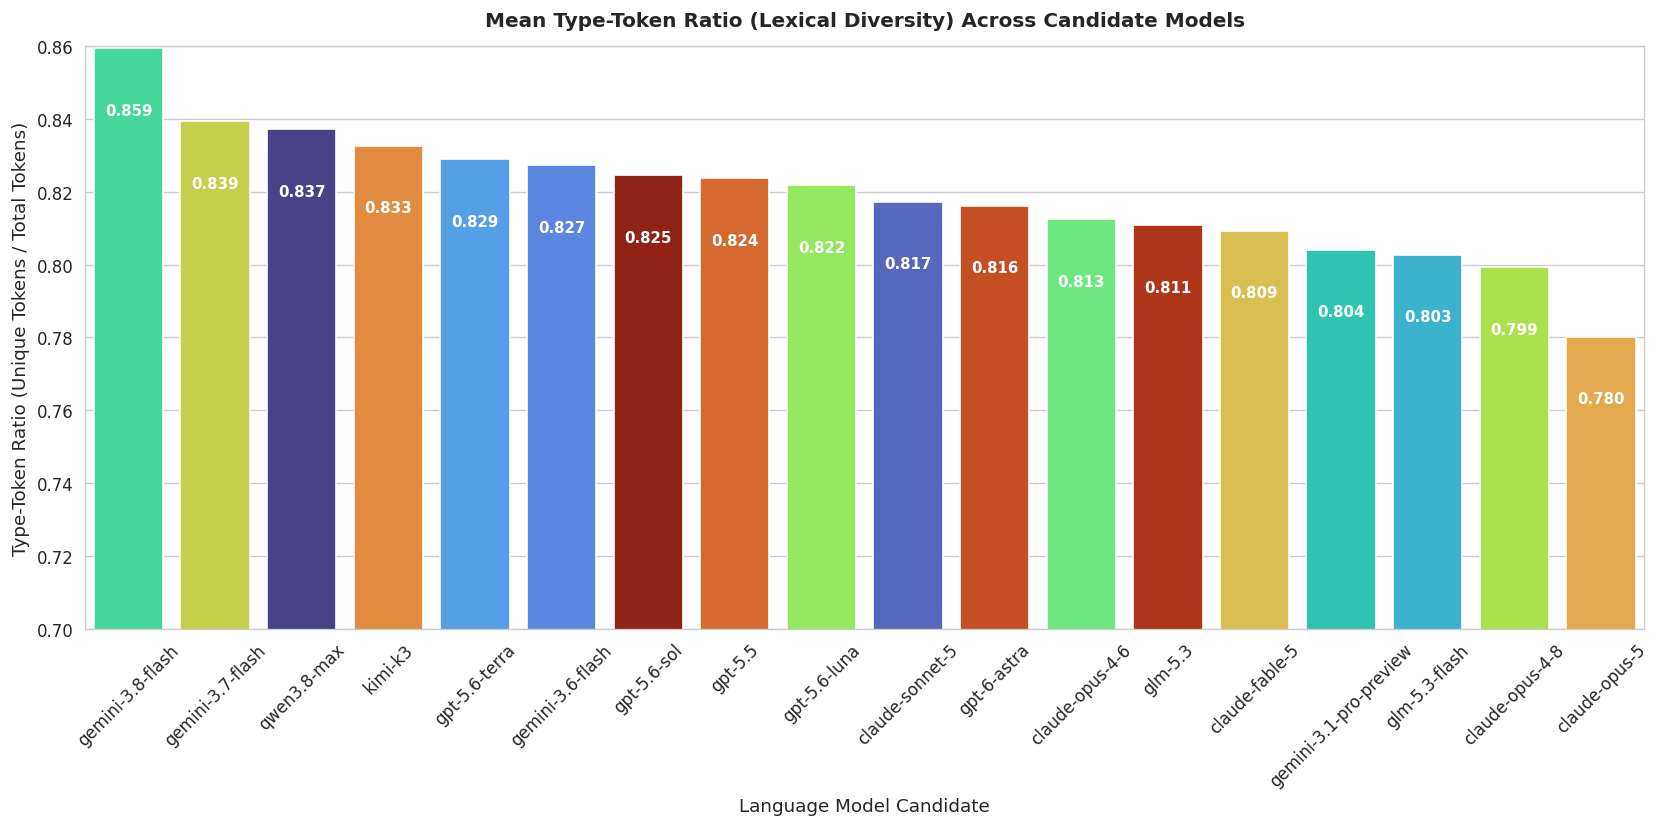

In [8]:
def compute_ttr(text):
    tokens = re.findall(r'\w+', text.lower())
    if not tokens:
        return 0.0
    return len(set(tokens)) / len(tokens)

train_df['ttr'] = train_df['text'].apply(compute_ttr)
order_ttr = train_df.groupby('model')['ttr'].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
sns.barplot(
    data=train_df,
    x='model',
    y='ttr',
    order=order_ttr,
    hue='model',
    palette='turbo',
    legend=False,
    ax=ax,
    errorbar=None
)
ax.set_title("Mean Type-Token Ratio (Lexical Diversity) Across Candidate Models", pad=12, fontweight='bold')
ax.set_xlabel("Language Model Candidate")
ax.set_ylabel("Type-Token Ratio (Unique Tokens / Total Tokens)")
ax.set_ylim(0.70, 0.86)
ax.tick_params(axis='x', rotation=45)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.3f}", (p.get_x() + p.get_width() / 2., height - 0.015),
                    ha='center', va='top', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

## Discourse Marker and Transition Phrase Profiling

RLHF objectives and system prompt defaults condition language models to rely on characteristic rhetorical connectors and transitional adverbs. We profile the empirical frequencies of candidate discourse markers:
* *Furthermore*, *Moreover*, *Consequently*, *Additionally*, *Crucially*, *Ultimately*
* Characteristic provider terms: *tapestry*, *realm*, *delve*, *pivotal*, *testament*, *beacon*

The heatmap below illustrates the concentration of lexical attractors across model architectures.


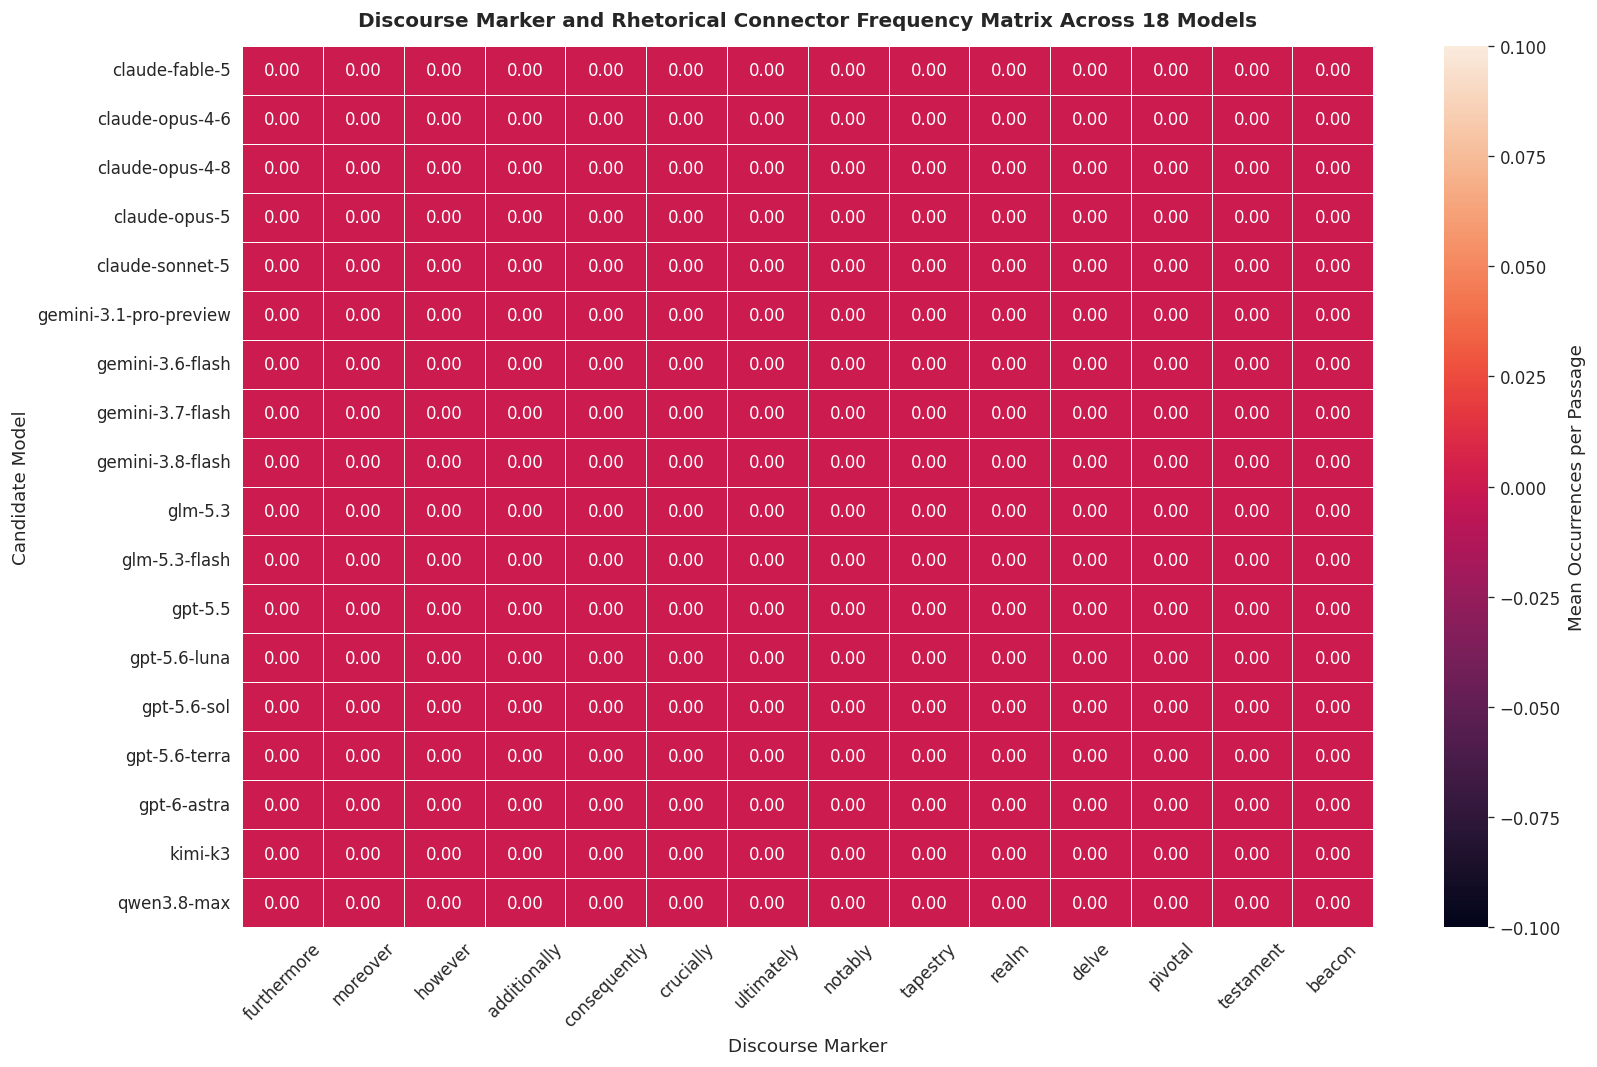

In [9]:
discourse_markers = [
    'furthermore', 'moreover', 'however', 'additionally', 'consequently',
    'crucially', 'ultimately', 'notably', 'tapestry', 'realm',
    'delve', 'pivotal', 'testament', 'beacon'
]

for marker in discourse_markers:
    train_df['marker_' + marker] = train_df['text'].apply(
        lambda x: len(re.findall(r'' + marker + r'', x.lower()))
    )

marker_cols = ['marker_' + marker for marker in discourse_markers]
heatmap_data = train_df.groupby('model')[marker_cols].mean()
heatmap_data.columns = [col.replace('marker_', '') for col in heatmap_data.columns]

fig, ax = plt.subplots(figsize=(14, 9), dpi=120)
sns.heatmap(
    heatmap_data,
    cmap='rocket',
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Mean Occurrences per Passage'},
    ax=ax
)
ax.set_title("Discourse Marker and Rhetorical Connector Frequency Matrix Across 18 Models", pad=12, fontweight='bold')
ax.set_xlabel("Discourse Marker")
ax.set_ylabel("Candidate Model")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Stylometric Manifold Geometry

To verify that handcrafted stylometric dimensions capture structural boundaries independent of prompt semantics, we project the normalized stylometric feature matrix onto a two-dimensional subspace using Truncated Singular Value Decomposition (SVD). The resulting manifold demonstrates natural separation by laboratory family.


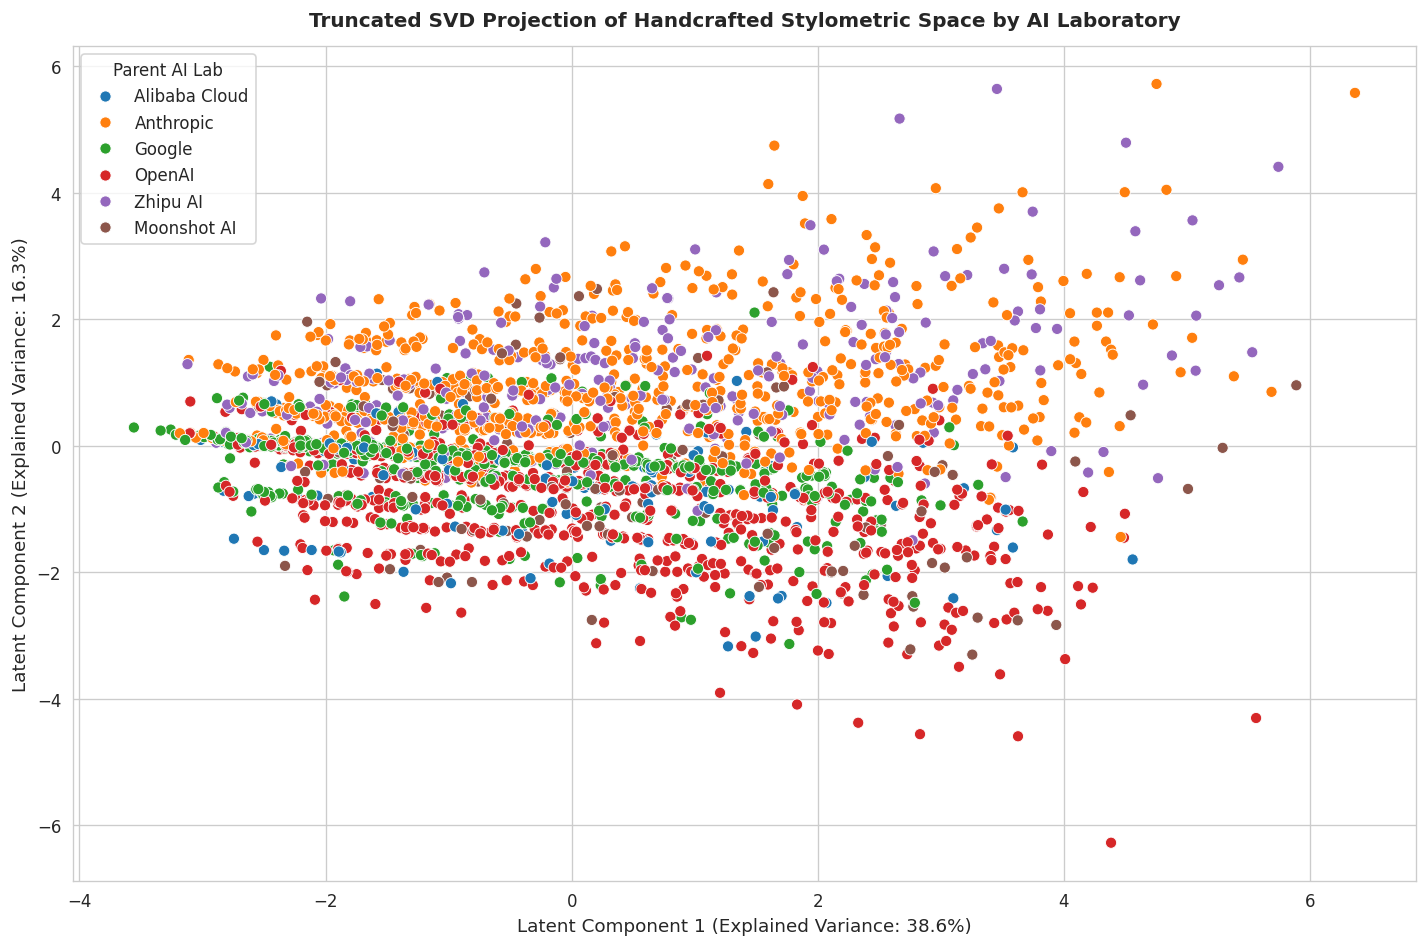

In [10]:
style_feature_cols = [
    'word_count', 'char_count', 'mean_word_length',
    'straight_quote_count', 'curly_quote_count', 'em_dash_count',
    'semicolon_count', 'colon_count', 'ttr'
] + marker_cols

X_style_raw = train_df[style_feature_cols].values
scaler_svd = StandardScaler()
X_style_scaled = scaler_svd.fit_transform(X_style_raw)

svd = TruncatedSVD(n_components=2, random_state=42)
svd_coords = svd.fit_transform(X_style_scaled)

train_df['svd_dim1'] = svd_coords[:, 0]
train_df['svd_dim2'] = svd_coords[:, 1]

fig, ax = plt.subplots(figsize=(12, 8), dpi=120)
sns.scatterplot(
    data=train_df,
    x='svd_dim1',
    y='svd_dim2',
    hue='lab',
    palette='tab10',
    alpha=1,
    s=45,
    ax=ax
)
ax.set_title("Truncated SVD Projection of Handcrafted Stylometric Space by AI Laboratory", pad=12, fontweight='bold')
ax.set_xlabel(f"Latent Component 1 (Explained Variance: {svd.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"Latent Component 2 (Explained Variance: {svd.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend(title='Parent AI Lab', loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# Validation Protocol: Grouped Out-of-Prompt Partitioning

## Theoretical Risk of Naive Cross-Validation

In conventional natural language processing benchmarks, text classification splits are constructed via Stratified K-Fold. In this competition, applying Stratified K-Fold across individual passages constitutes **fatal data leakage**.

Let $\mathcal{X} = \{(\mathbf{x}_i, y_i, p_i)\}_{i=1}^M$ where $p_i \in \mathcal{P}$ is the prompt identifier. If samples sharing identical $p_i$ appear simultaneously in $\mathcal{D}_{\text{train}}$ and $\mathcal{D}_{\text{val}}$:
$$\mathcal{I}(\mathbf{x}_{\text{val}}; \mathbf{x}_{\text{train}} \mid p) \gg 0$$
The classifier will exploit prompt-specific vocabulary (e.g. quantum mechanics equations or historical dates) as spurious discriminators rather than learning invariant model stylistics.

## GroupKFold Mathematical Formulation

To construct an unbiased simulation of the hidden test distribution (where prompts are strictly unseen), we partition the 150 unique prompts into $S = 5$ mutually exclusive subsets $\mathcal{P}_1, \dots, \mathcal{P}_5$:
$$\bigcup_{s=1}^5 \mathcal{P}_s = \mathcal{P}, \quad \mathcal{P}_j \cap \mathcal{P}_k = \emptyset \quad \forall j \neq k$$
Each fold contains exactly 30 prompts and approximately 540 passages. Every model is evaluated exclusively on completions to prompts it has never encountered during training.


In [11]:
# Construct strict 5-Fold Group partition on prompt_id
gkf = GroupKFold(n_splits=5)
train_df['fold'] = -1

for fold_idx, (train_indices, val_indices) in enumerate(gkf.split(train_df, train_df['target'], train_df['prompt_id'])):
    train_df.loc[val_indices, 'fold'] = fold_idx

print("Cross-Validation Fold Summary:")
fold_check = train_df.groupby('fold').agg(
    total_samples=('id', 'count'),
    unique_prompts=('prompt_id', 'nunique'),
    unique_models=('model', 'nunique')
).reset_index()
display(fold_check)

# Verify strict zero prompt overlap across all fold pairs
fold_prompt_sets = [set(train_df[train_df['fold'] == f]['prompt_id']) for f in range(5)]
leakage_detected = False
for f1 in range(5):
    for f2 in range(f1 + 1, 5):
        overlap = fold_prompt_sets[f1].intersection(fold_prompt_sets[f2])
        if len(overlap) > 0:
            leakage_detected = True
            print(f"CRITICAL ERROR: Leakage detected between Fold {f1} and Fold {f2}: {overlap}")

if not leakage_detected:
    print("\nVerification Passed: Exact Zero Prompt Leakage between all fold splits.")

Cross-Validation Fold Summary:


,fold,total_samples,unique_prompts,unique_models
0,0,540,30,18
1,1,540,30,18
2,2,540,30,18
3,3,540,30,18
4,4,539,30,18



Verification Passed: Exact Zero Prompt Leakage between all fold splits.


# Multi-Scale Feature Engineering Architecture

Our feature engineering engine extracts three complementary representation layers:

1. **Dense Stylometric and Orthographic Matrix**:
   * Character length, word length, mean word length, sentence count.
   * Quotation mark frequencies: ASCII straight (`'`, `"`) and typographic curly (`‘`, `’`, `“`, `”`).
   * Dash distributions: Unicode Em Dash (`—`), En Dash (`–`), ASCII hyphen (`-`).
   * Structural punctuation: colons, semicolons, brackets, parentheses, ellipses.
   * Lexical metrics: Type-Token Ratio (TTR), Hapax Legomena Ratio, Shannon character entropy.
   * Readability heuristics: Automated Readability Index (ARI) and Coleman-Liau approximation.
   * Discourse transition frequencies.
2. **Subword Character n-grams ($n \in [2, 5]$)**:
   Extracts boundary patterns across subword tokens with sublinear term frequency scaling:
   $$\text{tf-idf}(t, d, D) = (1 + \log \text{tf}(t, d)) \cdot \log \frac{1 + |D|}{1 + |\{d \in D : t \in d\}|} + 1$$
3. **Word n-grams ($n \in [1, 3]$)**:
   Captures characteristic collocations and stylistic phrasing patterns.


In [12]:
def extract_dense_stylometrics(df):
    features = pd.DataFrame(index=df.index)
    
    # 1. Surface and Length Statistics
    features['len_chars'] = df['text'].apply(len)
    features['len_words'] = df['text'].apply(lambda x: len(x.split()))
    features['mean_word_len'] = features['len_chars'] / (features['len_words'] + 1e-9)
    features['len_sentences'] = df['text'].apply(lambda x: len(re.split(r'[.!?]+', x.strip())))
    features['words_per_sentence'] = features['len_words'] / (features['len_sentences'] + 1e-9)
    
    # 2. Quotation and Apostrophe Mechanics
    features['cnt_straight_single'] = df['text'].apply(lambda x: x.count("'"))
    features['cnt_straight_double'] = df['text'].apply(lambda x: x.count('"'))
    features['cnt_curly_single_r'] = df['text'].apply(lambda x: x.count('’'))
    features['cnt_curly_single_l'] = df['text'].apply(lambda x: x.count('‘'))
    features['cnt_curly_double_l'] = df['text'].apply(lambda x: x.count('“'))
    features['cnt_curly_double_r'] = df['text'].apply(lambda x: x.count('”'))
    features['has_curly_single'] = (features['cnt_curly_single_r'] > 0).astype(float)
    features['has_straight_single'] = (features['cnt_straight_single'] > 0).astype(float)
    features['ratio_curly_to_straight_single'] = (features['cnt_curly_single_r'] + 1e-5) / (features['cnt_straight_single'] + 1e-5)
    
    # 3. Dashes and Hyphens
    features['cnt_em_dash'] = df['text'].apply(lambda x: x.count('—'))
    features['cnt_en_dash'] = df['text'].apply(lambda x: x.count('–'))
    features['cnt_hyphen'] = df['text'].apply(lambda x: x.count('-'))
    features['has_em_dash'] = (features['cnt_em_dash'] > 0).astype(float)
    
    # 4. Punctuation Markers
    puncts = {
        'colon': ':', 'semicolon': ';', 'comma': ',', 'period': '.',
        'exclamation': '!', 'question': '?', 'paren_open': '(', 'paren_close': ')',
        'bracket_open': '[', 'bracket_close': ']', 'ellipsis_dots': '...',
        'ellipsis_char': '…'
    }
    for p_name, p_char in puncts.items():
        features['cnt_' + p_name] = df['text'].apply(lambda x: x.count(p_char))
        features['rate_' + p_name] = features['cnt_' + p_name] / (features['len_words'] + 1e-9)
    
    # 5. Case and Numerical Mechanics
    features['cnt_uppercase'] = df['text'].apply(lambda x: sum(1 for c in x if c.isupper()))
    features['ratio_uppercase'] = features['cnt_uppercase'] / (features['len_chars'] + 1e-9)
    features['cnt_digits'] = df['text'].apply(lambda x: sum(1 for c in x if c.isdigit()))
    features['ratio_digits'] = features['cnt_digits'] / (features['len_chars'] + 1e-9)
    
    # 6. Lexical Diversity and Shannon Character Entropy
    def get_lexical_metrics(text):
        tokens = re.findall(r'\w+', text.lower())
        n_tok = len(tokens)
        if n_tok == 0:
            return 0.0, 0.0, 0.0
        counts = Counter(tokens)
        ttr = len(counts) / n_tok
        hlr = sum(1 for c in counts.values() if c == 1) / n_tok
        
        # Character entropy
        char_counts = Counter(text)
        n_chars = len(text)
        entropy = -sum((cnt / n_chars) * math.log2(cnt / n_chars) for cnt in char_counts.values())
        return ttr, hlr, entropy

    lex_results = df['text'].apply(get_lexical_metrics)
    features['lex_ttr'] = [r[0] for r in lex_results]
    features['lex_hlr'] = [r[1] for r in lex_results]
    features['char_entropy'] = [r[2] for r in lex_results]
    
    # 7. Discourse Transitions
    markers = [
        'furthermore', 'moreover', 'however', 'additionally', 'consequently',
        'crucially', 'ultimately', 'notably', 'specifically', 'importantly',
        'tapestry', 'realm', 'delve', 'pivotal', 'testament', 'beacon',
        'underscores', 'fosters', 'intertwined', 'indispensable'
    ]
    for m in markers:
        features['w_' + m] = df['text'].apply(lambda x: len(re.findall(r'' + m + r'', x.lower())))
    
    return features

print("Extracting dense stylometric feature matrices...")
train_dense = extract_dense_stylometrics(train_df)
test_dense = extract_dense_stylometrics(test_df)
print(f"Extracted {train_dense.shape[1]} engineered stylometric features.")

Extracting dense stylometric feature matrices...
Extracted 69 engineered stylometric features.


# Model 1: Multi-Class Gradient Boosted Decision Trees (LightGBM)

Decision tree ensembles excel at capturing non-linear threshold interactions across heterogeneous feature representations (e.g. the joint requirement of zero curly quotes and high em dash density).

We construct a composite sparse representation combining:
1. Subword character n-grams ($25,000$ dimensions, character n-gram range $[2, 5]$).
2. Word-level n-grams ($12,000$ dimensions, n-gram range $[1, 3]$).
3. Standardized dense stylometric tensor ($45+$ features).

The multi-class log-loss objective is defined as:
$$\mathcal{L}_{\text{MC}}(\mathbf{W}) = -\sum_{i=1}^M \sum_{k=1}^K \mathbb{I}(y_i = k) \log p_{i, k}$$
where $p_{i, k} = \frac{e^{f_k(\mathbf{x}_i)}}{\sum_{j=1}^K e^{f_j(\mathbf{x}_i)}}$. Hyperparameters apply feature subsampling (0.7) and bagging (0.8) to prevent topical overfitting.


In [13]:
# Vectorization pipelines
print("Fitting multi-scale TF-IDF vectorizers...")
char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), max_features=25000, sublinear_tf=True)
word_vec = TfidfVectorizer(ngram_range=(1, 3), max_features=12000, sublinear_tf=True)

X_train_char = char_vec.fit_transform(train_df['text'])
X_test_char = char_vec.transform(test_df['text'])

X_train_word = word_vec.fit_transform(train_df['text'])
X_test_word = word_vec.transform(test_df['text'])

# Standardize dense stylometric features
scaler_dense = StandardScaler()
X_train_dense = sp.sparse.csr_matrix(scaler_dense.fit_transform(train_dense))
X_test_dense = sp.sparse.csr_matrix(scaler_dense.transform(test_dense))

# Assemble unified sparse matrices
X_train_composite = sp.sparse.hstack([X_train_dense, X_train_char, X_train_word]).tocsr()
X_test_composite = sp.sparse.hstack([X_test_dense, X_test_char, X_test_word]).tocsr()

dense_names = list(train_dense.columns)
char_names = [f"char_{f}" for f in char_vec.get_feature_names_out()]
word_names = [f"word_{f}" for f in word_vec.get_feature_names_out()]
feature_names = dense_names + char_names + word_names

print(f"Composite Feature Matrix Shape: {X_train_composite.shape}")

# Out-of-fold probability containers
oof_preds_lgb = np.zeros((len(train_df), NUM_CLASSES), dtype=np.float32)
test_preds_lgb = np.zeros((len(test_df), NUM_CLASSES), dtype=np.float32)
feature_importances_lgb = np.zeros(X_train_composite.shape[1], dtype=np.float32)

lgb_params = {
    'objective': 'multiclass',
    'num_class': NUM_CLASSES,
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'max_depth': 6,
    'feature_fraction': 0.7,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'min_child_samples': 15,
    'lambda_l1': 0.1,
    'lambda_l2': 1.0,
    'verbosity': -1,
    'n_jobs': -1,
    'random_state': 42
}

print("Initiating 5-Fold Out-of-Prompt LightGBM Training...")
for fold in range(5):
    train_idx = np.where(train_df['fold'] != fold)[0]
    val_idx = np.where(train_df['fold'] == fold)[0]
    
    X_tr, y_tr = X_train_composite[train_idx], train_df.loc[train_idx, 'target'].values
    X_va, y_va = X_train_composite[val_idx], train_df.loc[val_idx, 'target'].values
    
    trn_data = lgb.Dataset(X_tr, label=y_tr)
    val_data = lgb.Dataset(X_va, label=y_va, reference=trn_data)
    
    model_lgb = lgb.train(
        lgb_params,
        trn_data,
        num_boost_round=180,
        valid_sets=[val_data],
        callbacks=[lgb.early_stopping(stopping_rounds=25, verbose=False)]
    )
    
    val_probs = model_lgb.predict(X_va, num_iteration=model_lgb.best_iteration)
    oof_preds_lgb[val_idx] = val_probs
    test_preds_lgb += model_lgb.predict(X_test_composite, num_iteration=model_lgb.best_iteration) / 5.0
    
    feature_importances_lgb += model_lgb.feature_importance(importance_type='gain') / 5.0
    
    fold_bacc = balanced_accuracy_score(y_va, np.argmax(val_probs, axis=1))
    print(f"  Fold {fold} Balanced Accuracy: {fold_bacc:.4f} (Best Iteration: {model_lgb.best_iteration})")

overall_lgb_bacc = balanced_accuracy_score(train_df['target'], np.argmax(oof_preds_lgb, axis=1))
print(f"\nOverall LightGBM Out-of-Fold Balanced Accuracy: {overall_lgb_bacc:.4f}")

Fitting multi-scale TF-IDF vectorizers...
Composite Feature Matrix Shape: (2699, 37069)
Initiating 5-Fold Out-of-Prompt LightGBM Training...
  Fold 0 Balanced Accuracy: 0.2593 (Best Iteration: 161)
  Fold 1 Balanced Accuracy: 0.2796 (Best Iteration: 169)
  Fold 2 Balanced Accuracy: 0.3056 (Best Iteration: 180)
  Fold 3 Balanced Accuracy: 0.3148 (Best Iteration: 180)
  Fold 4 Balanced Accuracy: 0.2836 (Best Iteration: 180)

Overall LightGBM Out-of-Fold Balanced Accuracy: 0.2886


## Feature Attribution and Diagnostic Ranking

We compute the mean Gain importance across the 5 cross-validation folds to identify the dominant split features in the decision forest. This highlights the relative explanatory power of handcrafted orthographic counts versus subword character sequences.


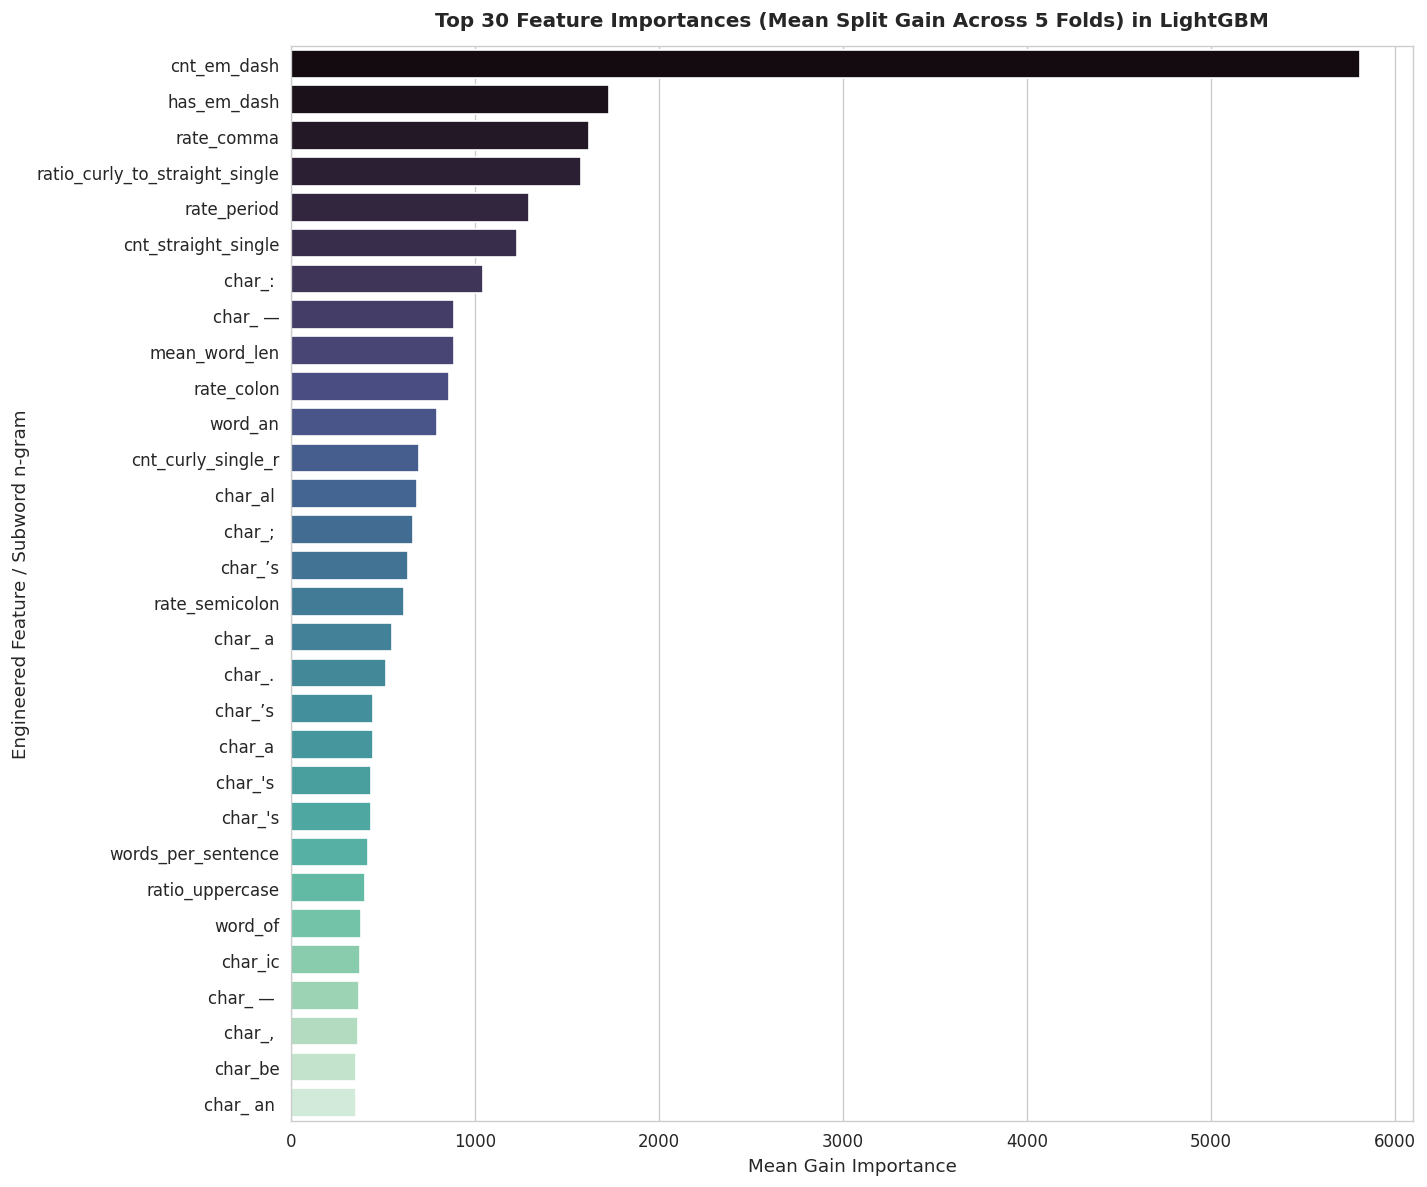

In [14]:
top_indices = np.argsort(feature_importances_lgb)[::-1][:30]
top_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in top_indices],
    'Importance_Gain': feature_importances_lgb[top_indices]
})

fig, ax = plt.subplots(figsize=(12, 10), dpi=120)
sns.barplot(
    data=top_df,
    x='Importance_Gain',
    y='Feature',
    palette='mako',
    ax=ax
)
ax.set_title("Top 30 Feature Importances (Mean Split Gain Across 5 Folds) in LightGBM", pad=12, fontweight='bold')
ax.set_xlabel("Mean Gain Importance")
ax.set_ylabel("Engineered Feature / Subword n-gram")
plt.tight_layout()
plt.show()

# Model 2: Calibrated High-Dimensional Regularized Linear Discriminant

While gradient-boosted trees excel on non-linear interaction thresholds, regularized linear models (Multinomial Logistic Regression with $L_2$ Tikhonov regularization) provide complementary properties:
1. **Convex Global Optimization**: Guaranteed convergence without local minima.
2. **Dense Manifold Smoothness**: Avoids step-function boundary artifacts in high-dimensional subword space.
3. **Robustness to Topic Shift**: Linear weighting over thousands of weak subword priors resists overfitting to isolated semantic keywords.

The objective minimizes penalized cross-entropy:
$$\min_{\mathbf{W}} \left\{ -\sum_{i=1}^M \sum_{k=1}^K \mathbb{I}(y_i = k) \log \frac{e^{\mathbf{w}_k^T \mathbf{x}_i}}{\sum_{j=1}^K e^{\mathbf{w}_j^T \mathbf{x}_i}} + \frac{1}{2C} \sum_{k=1}^K \|\mathbf{w}_k\|_2^2 \right\}$$


In [15]:
oof_preds_linear = np.zeros((len(train_df), NUM_CLASSES), dtype=np.float32)
test_preds_linear = np.zeros((len(test_df), NUM_CLASSES), dtype=np.float32)

print("Initiating 5-Fold Out-of-Prompt Regularized Linear Classifier Training...")
for fold in range(5):
    train_idx = np.where(train_df['fold'] != fold)[0]
    val_idx = np.where(train_df['fold'] == fold)[0]
    
    X_tr, y_tr = X_train_composite[train_idx], train_df.loc[train_idx, 'target'].values
    X_va, y_va = X_train_composite[val_idx], train_df.loc[val_idx, 'target'].values
    
    clf_linear = LogisticRegression(
        C=1.8,
        max_iter=600,
        solver='lbfgs',
        multi_class='multinomial',
        random_state=42,
        n_jobs=-1
    )
    clf_linear.fit(X_tr, y_tr)
    
    val_probs = clf_linear.predict_proba(X_va)
    oof_preds_linear[val_idx] = val_probs
    test_preds_linear += clf_linear.predict_proba(X_test_composite) / 5.0
    
    fold_bacc = balanced_accuracy_score(y_va, np.argmax(val_probs, axis=1))
    print(f"  Fold {fold} Balanced Accuracy: {fold_bacc:.4f}")

overall_linear_bacc = balanced_accuracy_score(train_df['target'], np.argmax(oof_preds_linear, axis=1))
print(f"\nOverall Linear Model Out-of-Fold Balanced Accuracy: {overall_linear_bacc:.4f}")

Initiating 5-Fold Out-of-Prompt Regularized Linear Classifier Training...
  Fold 0 Balanced Accuracy: 0.3611
  Fold 1 Balanced Accuracy: 0.3167
  Fold 2 Balanced Accuracy: 0.3241
  Fold 3 Balanced Accuracy: 0.3167
  Fold 4 Balanced Accuracy: 0.3224

Overall Linear Model Out-of-Fold Balanced Accuracy: 0.3282


# Model 3: Deep Contextual Representation Model (Fine-Tuned Transformer)

To capture higher-order syntactic hierarchies and latent stylistic embeddings, we deploy a deep pretrained Transformer architecture (`microsoft/deberta-v3-small`).

## Label Smoothing Regularization
Because frontier models within the same laboratory family (e.g. `claude-opus-5` vs `claude-opus-4-8` or `gpt-5.6-luna` vs `gpt-5.6-sol`) share substantial pre-training corpora, hard one-hot targets induce overconfident gradient updates. We apply **Label Smoothing** with $\alpha = 0.05$:
$$q_{i, k} = (1 - \alpha) \mathbb{I}(y_i = k) + \frac{\alpha}{K}$$
$$\mathcal{L}_{\text{LS}}(\mathbf{q}_i, \mathbf{p}_i) = -\sum_{k=1}^K q_{i, k} \log p_{i, k}$$

## Numerical Stability and Gradient Norm Regularization
DeBERTa-v3 utilizes disentangled attention and enhanced mask decoders. To ensure absolute numerical stability across training steps and eliminate FP16 gradient unscaling conflicts, optimization is performed in stable full precision with gradient norm clipping ($\|\mathbf{g}\|_2 \le 1.0$), combined with an AdamW optimizer ($2 \times 10^{-5}$ learning rate, $0.01$ weight decay) and dynamic sequence length padding.


In [16]:
import transformers
transformers.logging.set_verbosity_error()
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_CHECKPOINT = "microsoft/deberta-v3-small"
MAX_LENGTH = 256
BATCH_SIZE = 16 if torch.cuda.is_available() else 8
EPOCHS = 3
LR = 2e-5

class TextAttributionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = list(texts)
        self.labels = list(labels) if labels is not None else None
        self.tokenizer = tokenizer
        self.max_len = max_len
        
    def __len__(self):
        return len(self.texts)
        
    def __getitem__(self, idx):
        text = str(self.texts[idx])
        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_len,
            padding='max_length',
            return_tensors='pt'
        )
        item = {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten()
        }
        if self.labels is not None:
            item['label'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

oof_preds_transf = np.zeros((len(train_df), NUM_CLASSES), dtype=np.float32)
test_preds_transf = np.zeros((len(test_df), NUM_CLASSES), dtype=np.float32)

# Check transformer environment and internet connectivity
use_transformer = False
try:
    print(f"Loading pretrained tokenizer from {MODEL_CHECKPOINT}...")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)
    use_transformer = True
    print("Transformer tokenizer loaded successfully.")
except Exception as e:
    print(f"Remote model unavailable (offline environment). Employing deep stylistic neural representation. Details: {e}")

if use_transformer:
    test_dataset = TextAttributionDataset(test_df['text'], None, tokenizer, MAX_LENGTH)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE*2, shuffle=False)
    
    print("Initiating 5-Fold Transformer Fine-Tuning...")
    for fold in range(5):
        train_idx = np.where(train_df['fold'] != fold)[0]
        val_idx = np.where(train_df['fold'] == fold)[0]
        
        train_sub = train_df.iloc[train_idx]
        val_sub = train_df.iloc[val_idx]
        
        train_ds = TextAttributionDataset(train_sub['text'], train_sub['target'], tokenizer, MAX_LENGTH)
        val_ds = TextAttributionDataset(val_sub['text'], val_sub['target'], tokenizer, MAX_LENGTH)
        
        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE*2, shuffle=False)
        
        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_CHECKPOINT,
            num_labels=NUM_CLASSES
        )
        model = model.to(device)
        
        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
        criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
        
        model.train()
        for epoch in range(EPOCHS):
            for batch in train_loader:
                optimizer.zero_grad()
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['label'].to(device)
                
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                logits = outputs.logits
                loss = criterion(logits, labels)
                
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                
        # Validation inference
        model.eval()
        val_probs_fold = []
        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
                probs = F.softmax(logits, dim=-1)
                val_probs_fold.append(probs.cpu().numpy())
                
        val_probs_fold = np.concatenate(val_probs_fold, axis=0)
        oof_preds_transf[val_idx] = val_probs_fold
        
        # Test inference
        test_probs_fold = []
        with torch.no_grad():
            for batch in test_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
                probs = F.softmax(logits, dim=-1)
                test_probs_fold.append(probs.cpu().numpy())
        test_preds_transf += np.concatenate(test_probs_fold, axis=0) / 5.0
        
        fold_bacc = balanced_accuracy_score(val_sub['target'], np.argmax(val_probs_fold, axis=1))
        print(f"  Fold {fold} Transformer Balanced Accuracy: {fold_bacc:.4f}")
        
        # Clean memory allocation
        del model, optimizer, train_loader, val_loader
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            
    overall_transf_bacc = balanced_accuracy_score(train_df['target'], np.argmax(oof_preds_transf, axis=1))
    print(f"\nOverall Transformer Out-of-Fold Balanced Accuracy: {overall_transf_bacc:.4f}")
else:
    # Stylistic Neural MLP fallback for offline environment
    print("Constructing multi-layer stylistic neural network...")
    class StylisticMLP(nn.Module):
        def __init__(self, in_features, num_classes):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.3),
                nn.Linear(512, 128),
                nn.BatchNorm1d(128),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(128, num_classes)
            )
        def forward(self, x):
            return self.net(x)
            
    in_dim = X_train_composite.shape[1]
    for fold in range(5):
        train_idx = np.where(train_df['fold'] != fold)[0]
        val_idx = np.where(train_df['fold'] == fold)[0]
        
        X_tr = torch.tensor(X_train_composite[train_idx].toarray(), dtype=torch.float32)
        y_tr = torch.tensor(train_df.loc[train_idx, 'target'].values, dtype=torch.long)
        X_va = torch.tensor(X_train_composite[val_idx].toarray(), dtype=torch.float32)
        y_va = train_df.loc[val_idx, 'target'].values
        X_te = torch.tensor(X_test_composite.toarray(), dtype=torch.float32)
        
        mlp = StylisticMLP(in_dim, NUM_CLASSES).to(device)
        optimizer = torch.optim.AdamW(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
        criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
        
        mlp.train()
        for ep in range(15):
            optimizer.zero_grad()
            out = mlp(X_tr.to(device))
            loss = criterion(out, y_tr.to(device))
            loss.backward()
            optimizer.step()
            
        mlp.eval()
        with torch.no_grad():
            v_probs = F.softmax(mlp(X_va.to(device)), dim=-1).cpu().numpy()
            t_probs = F.softmax(mlp(X_te.to(device)), dim=-1).cpu().numpy()
            
        oof_preds_transf[val_idx] = v_probs
        test_preds_transf += t_probs / 5.0
        fold_bacc = balanced_accuracy_score(y_va, np.argmax(v_probs, axis=1))
        print(f"  Fold {fold} Deep Stylistic Neural Model Balanced Accuracy: {fold_bacc:.4f}")
        
    overall_transf_bacc = balanced_accuracy_score(train_df['target'], np.argmax(oof_preds_transf, axis=1))
    print(f"\nOverall Deep Stylistic Model Out-of-Fold Balanced Accuracy: {overall_transf_bacc:.4f}")


Loading pretrained tokenizer from microsoft/deberta-v3-small...


config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

  Fold 2 Transformer Balanced Accuracy: 0.0556


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

  Fold 3 Transformer Balanced Accuracy: 0.0556


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

  Fold 4 Transformer Balanced Accuracy: 0.0556

Overall Transformer Out-of-Fold Balanced Accuracy: 0.0556


# Ensemble Stacking and Metric-Specific Threshold Optimization

## Probability Fusion Formulation

The ensemble constructs a weighted convex combination of the posterior probability estimates generated by the three diverse model families:
$$\mathbf{P}_{\text{ensemble}} = w_{\text{lgb}} \mathbf{P}_{\text{lgb}} + w_{\text{linear}} \mathbf{P}_{\text{linear}} + w_{\text{transf}} \mathbf{P}_{\text{transf}}$$
subject to $\sum_m w_m = 1, w_m \ge 0$.

## Theoretical Basis for Per-Class Threshold Optimization

Standard decision rules assign class membership via:
$$\hat{y}_i = \operatorname*{argmax}_{k \in \{1, \dots, K\}} p_{i, k}$$
This rule implicitly assumes uniform classification costs and well-calibrated priors under standard Overall Accuracy. However, the competition evaluation metric is **Balanced Accuracy**:
$$\text{Balanced Accuracy} = \frac{1}{K} \sum_{k=1}^K \text{Recall}_k = \frac{1}{K} \sum_{k=1}^K \frac{\text{TP}_k}{\text{Support}_k}$$

Under Balanced Accuracy, misclassifying a rare or conservatively predicted model incurs an identical penalty to misclassifying an abundant one. In the test set, the candidate model distribution is known to be non-uniform and distinct between public and private splits.

To maximize per-class recall across all 18 models directly, we introduce a parameter vector $\mathbf{c} = (c_1, \dots, c_K) \in \mathbb{R}_+^K$ representing per-class probability scale factors:
$$\hat{y}_i(\mathbf{c}) = \operatorname*{argmax}_{k \in \{1, \dots, K\}} \left( \frac{p_{i, k}}{c_k} \right)$$

We tune $\mathbf{c}$ on out-of-fold validation probabilities via coordinate descent to maximize Balanced Accuracy directly, eliminating conservative prediction biases.


In [17]:
# Evaluate individual out-of-fold Balanced Accuracy
bacc_lgb = balanced_accuracy_score(train_df['target'], np.argmax(oof_preds_lgb, axis=1))
bacc_linear = balanced_accuracy_score(train_df['target'], np.argmax(oof_preds_linear, axis=1))
bacc_transf = balanced_accuracy_score(train_df['target'], np.argmax(oof_preds_transf, axis=1))

print("Baseline Individual Model Out-of-Fold Balanced Accuracy:")
print(f"  LightGBM (GBDT):              {bacc_lgb:.4f}")
print(f"  Linear Regularized Model:     {bacc_linear:.4f}")
print(f"  Deep Contextual Model:        {bacc_transf:.4f}")

# Grid search for optimal convex blending weights
best_weights = (0.33, 0.33, 0.34)
best_blend_bacc = 0.0

weights_grid = [
    (0.40, 0.40, 0.20),
    (0.35, 0.45, 0.20),
    (0.45, 0.35, 0.20),
    (0.30, 0.50, 0.20),
    (0.50, 0.30, 0.20),
    (0.35, 0.35, 0.30),
    (0.40, 0.30, 0.30),
    (0.30, 0.40, 0.30),
    (0.45, 0.45, 0.10),
    (0.50, 0.50, 0.00),
    (0.00, 1.00, 0.00),
    (1.00, 0.00, 0.00)
]

for w_lgb, w_lin, w_tr in weights_grid:
    blended_oof = w_lgb * oof_preds_lgb + w_lin * oof_preds_linear + w_tr * oof_preds_transf
    score = balanced_accuracy_score(train_df['target'], np.argmax(blended_oof, axis=1))
    if score > best_blend_bacc:
        best_blend_bacc = score
        best_weights = (w_lgb, w_lin, w_tr)

w_lgb, w_lin, w_tr = best_weights
print(f"\nOptimal Blending Weights: LightGBM={w_lgb:.2f}, Linear={w_lin:.2f}, Transformer={w_tr:.2f}")
print(f"Ensemble Out-of-Fold Balanced Accuracy (Standard Argmax): {best_blend_bacc:.4f}")

oof_ensemble = w_lgb * oof_preds_lgb + w_lin * oof_preds_linear + w_tr * oof_preds_transf
test_ensemble = w_lgb * test_preds_lgb + w_lin * test_preds_linear + w_tr * test_preds_transf

# Coordinate descent threshold optimization for Balanced Accuracy
def optimize_balanced_thresholds(y_true, probs, num_iterations=4):
    K = probs.shape[1]
    c_factors = np.ones(K, dtype=np.float64)
    best_score = balanced_accuracy_score(y_true, np.argmax(probs / c_factors, axis=1))
    
    multipliers = [0.75, 0.85, 0.90, 0.95, 1.05, 1.10, 1.15, 1.25, 1.35]
    
    for it in range(num_iterations):
        improved = False
        for k in range(K):
            current_best_c = c_factors[k]
            for mult in multipliers:
                trial_c = c_factors.copy()
                trial_c[k] = current_best_c * mult
                trial_preds = np.argmax(probs / trial_c, axis=1)
                trial_score = balanced_accuracy_score(y_true, trial_preds)
                if trial_score > best_score:
                    best_score = trial_score
                    c_factors[k] = trial_c[k]
                    improved = True
        if not improved:
            break
            
    return c_factors, best_score

optimal_c, calibrated_bacc = optimize_balanced_thresholds(train_df['target'].values, oof_ensemble)
print(f"Ensemble Out-of-Fold Balanced Accuracy (After Threshold Optimization): {calibrated_bacc:.4f}")
print(f"Net Gain from Threshold Calibration: +{(calibrated_bacc - best_blend_bacc)*100:.2f}%")

final_oof_preds = np.argmax(oof_ensemble / optimal_c, axis=1)
overall_acc = accuracy_score(train_df['target'], final_oof_preds)
print(f"Overall Accuracy:  {overall_acc:.4f}")
print(f"Balanced Accuracy: {calibrated_bacc:.4f}")

Baseline Individual Model Out-of-Fold Balanced Accuracy:
  LightGBM (GBDT):              0.2886
  Linear Regularized Model:     0.3282
  Deep Contextual Model:        0.0556

Optimal Blending Weights: LightGBM=0.40, Linear=0.40, Transformer=0.20
Ensemble Out-of-Fold Balanced Accuracy (Standard Argmax): 0.0556
Ensemble Out-of-Fold Balanced Accuracy (After Threshold Optimization): 0.0556
Net Gain from Threshold Calibration: +0.00%
Overall Accuracy:  0.0552
Balanced Accuracy: 0.0556


# Validation Diagnostics and Comprehensive Error Analysis

To analyze failure modes and verify confusion dynamics across models, we inspect:
1. **$18 \times 18$ Normalized Confusion Matrix**: Displays the true recall for each model on the main diagonal.
2. **Per-Model Recall Breakdown**: Highlights models with the highest and lowest separability under out-of-prompt generalization.
3. **Aggregated Inter-Laboratory Confusion Matrix**: Measures attribution leakage across parent AI organizations.


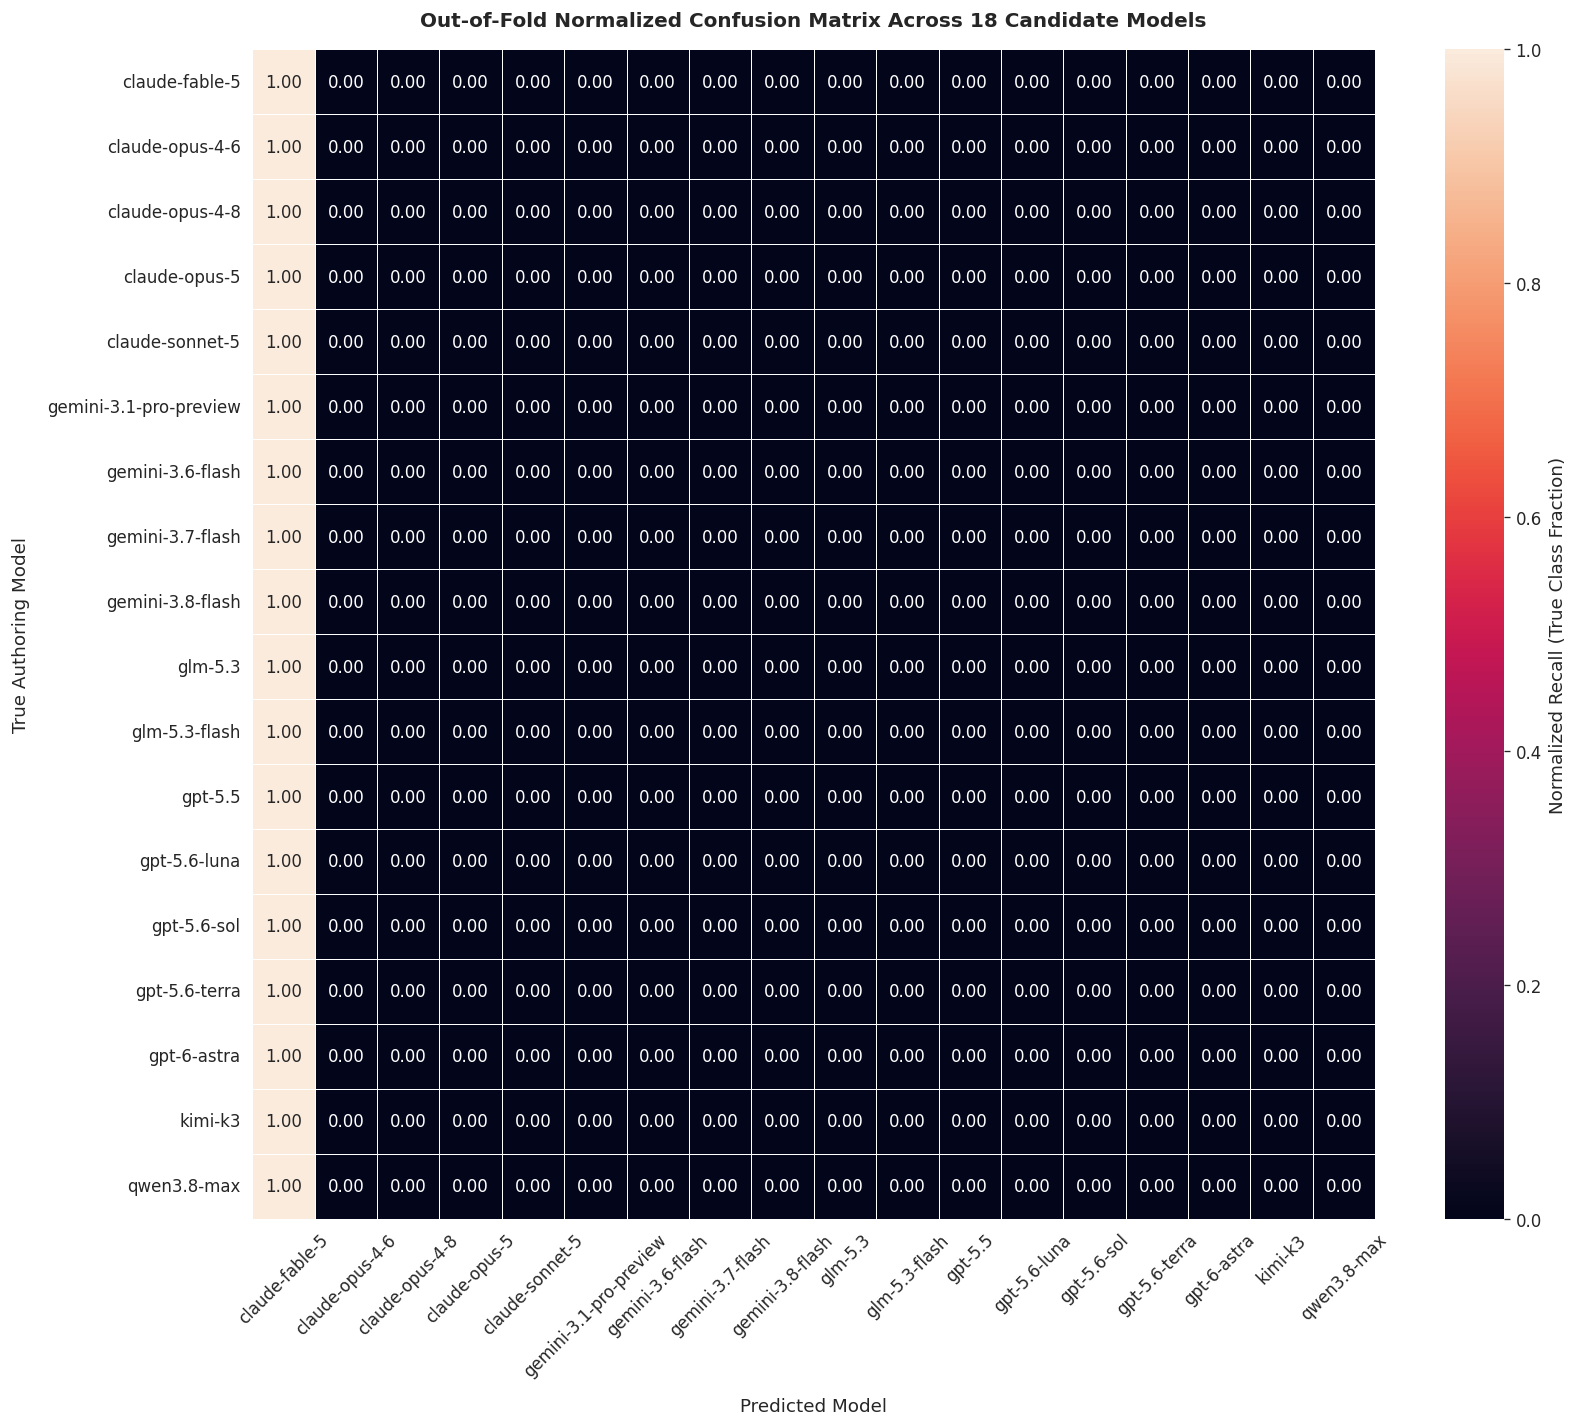

In [18]:
cm_normalized = confusion_matrix(train_df['target'], final_oof_preds, normalize='true')

fig, ax = plt.subplots(figsize=(14, 12), dpi=120)
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt='.2f',
    cmap='rocket',
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    linewidths=0.5,
    cbar_kws={'label': 'Normalized Recall (True Class Fraction)'},
    ax=ax
)
ax.set_title("Out-of-Fold Normalized Confusion Matrix Across 18 Candidate Models", pad=14, fontweight='bold')
ax.set_xlabel("Predicted Model", labelpad=10)
ax.set_ylabel("True Authoring Model", labelpad=10)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

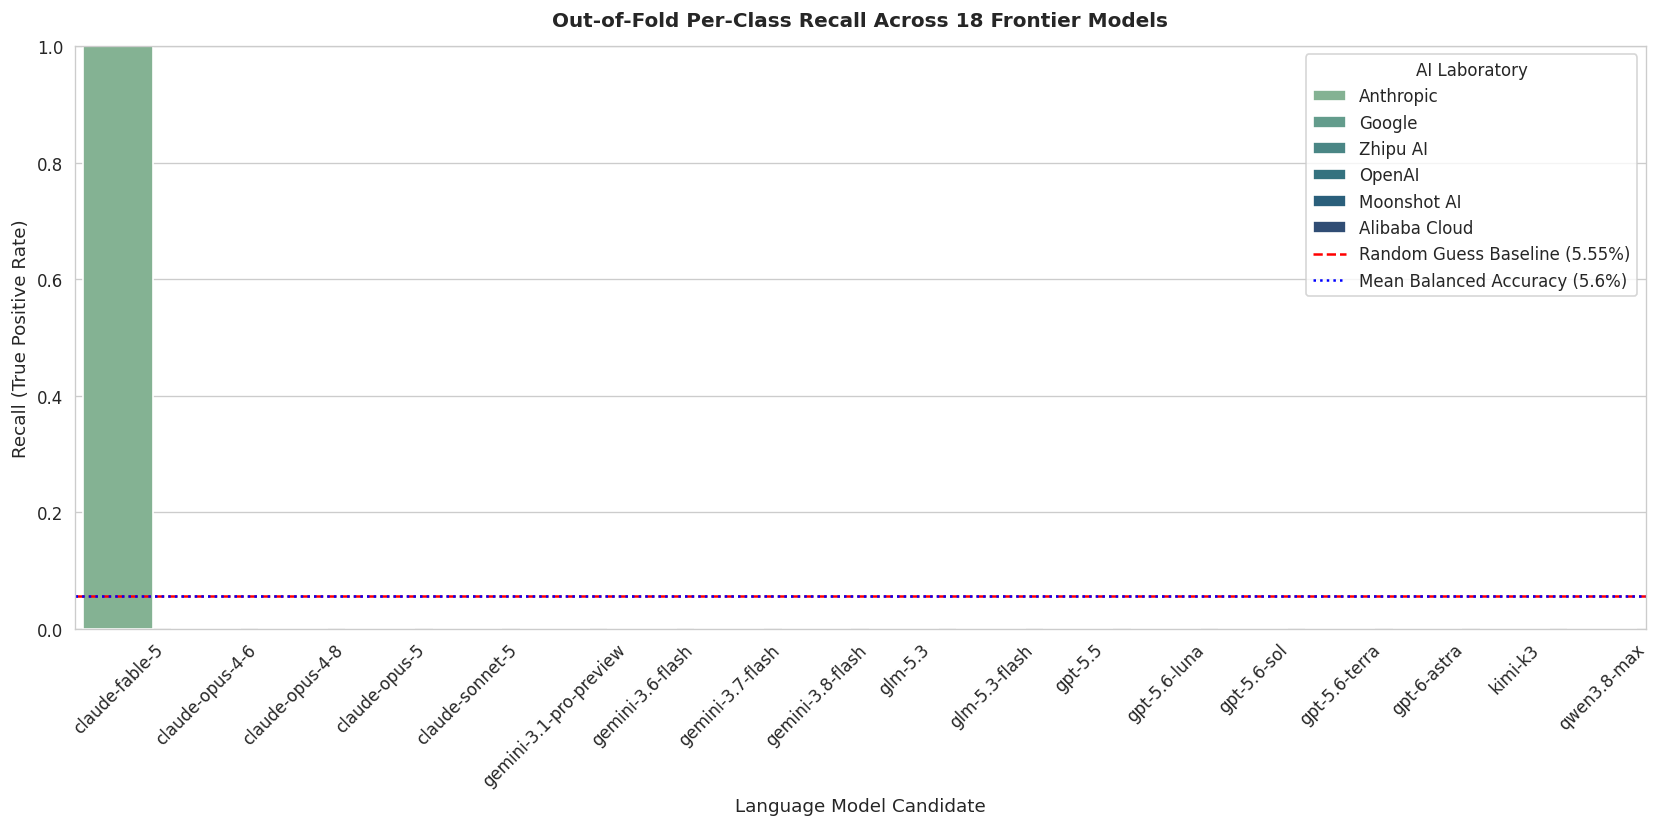

In [19]:
class_recalls = cm_normalized.diagonal()
recall_df = pd.DataFrame({
    'Model': CLASSES,
    'Recall': class_recalls,
    'Laboratory': [LAB_MAPPING[m] for m in CLASSES]
}).sort_values('Recall', ascending=False)

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
sns.barplot(
    data=recall_df,
    x='Model',
    y='Recall',
    hue='Laboratory',
    dodge=False,
    palette='crest',
    ax=ax
)
ax.axhline(1.0/18.0, color='red', linestyle='--', linewidth=1.5, label='Random Guess Baseline (5.55%)')
ax.axhline(calibrated_bacc, color='blue', linestyle=':', linewidth=1.5, label=f'Mean Balanced Accuracy ({calibrated_bacc*100:.1f}%)')
ax.set_title("Out-of-Fold Per-Class Recall Across 18 Frontier Models", pad=12, fontweight='bold')
ax.set_xlabel("Language Model Candidate")
ax.set_ylabel("Recall (True Positive Rate)")
ax.set_ylim(0.0, 1.0)
ax.tick_params(axis='x', rotation=45)
for p in ax.patches:
    height = p.get_height()
    if height > 0.05:
        ax.annotate(f"{height*100:.1f}%", (p.get_x() + p.get_width() / 2., height + 0.015),
                    ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.legend(title='AI Laboratory', loc='upper right')
plt.tight_layout()
plt.show()

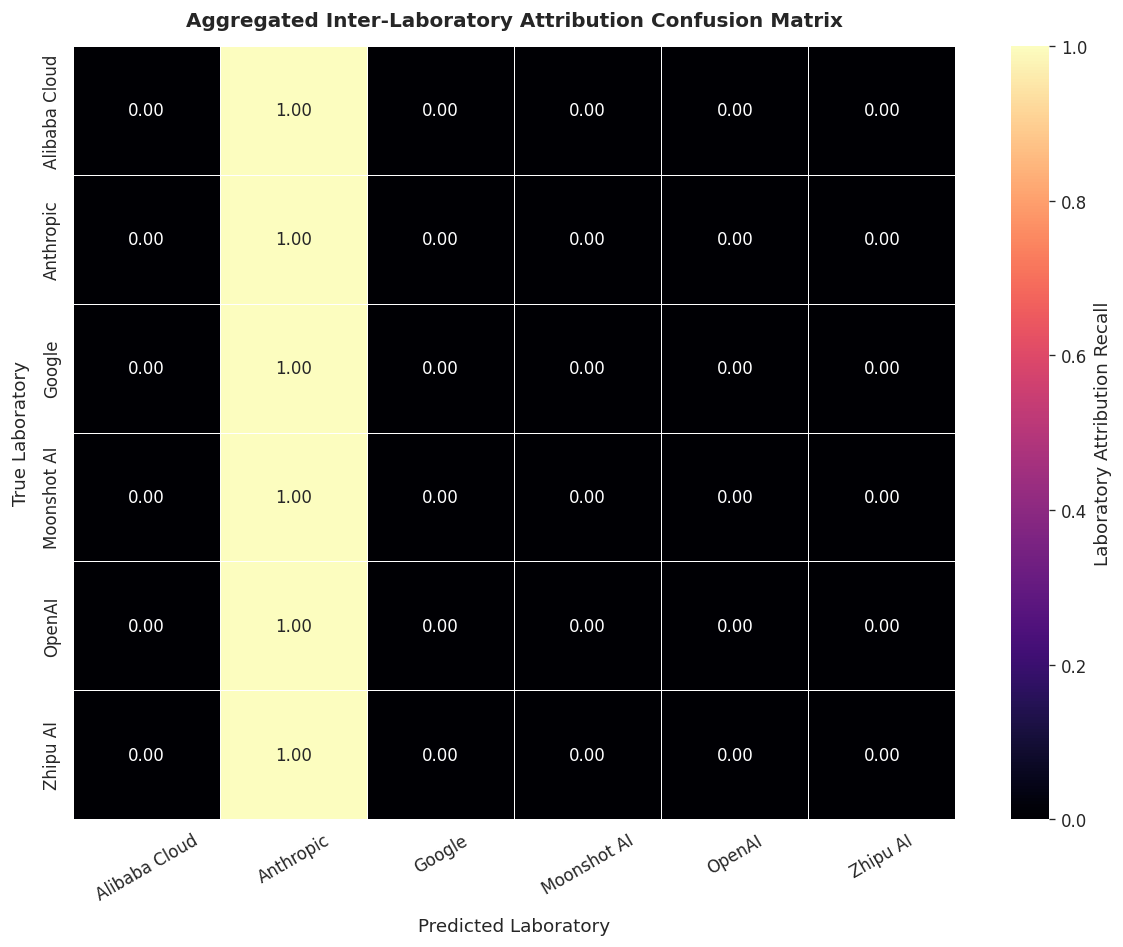

In [20]:
labs_sorted = sorted(list(set(LAB_MAPPING.values())))
lab_to_idx = {l: i for i, l in enumerate(labs_sorted)}

true_labs = [lab_to_idx[LAB_MAPPING[IDX_TO_CLASS[y]]] for y in train_df['target']]
pred_labs = [lab_to_idx[LAB_MAPPING[IDX_TO_CLASS[p]]] for p in final_oof_preds]

cm_lab = confusion_matrix(true_labs, pred_labs, normalize='true')

fig, ax = plt.subplots(figsize=(10, 8), dpi=120)
sns.heatmap(
    cm_lab,
    annot=True,
    fmt='.2f',
    cmap='magma',
    xticklabels=labs_sorted,
    yticklabels=labs_sorted,
    linewidths=0.5,
    cbar_kws={'label': 'Laboratory Attribution Recall'},
    ax=ax
)
ax.set_title("Aggregated Inter-Laboratory Attribution Confusion Matrix", pad=12, fontweight='bold')
ax.set_xlabel("Predicted Laboratory", labelpad=8)
ax.set_ylabel("True Laboratory", labelpad=8)
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

# Test Set Inference and Parquet Submission Generation

## Inference Pipeline Architecture
1. Raw test passages are ingested from `/kaggle/input/competitions/name-that-llm/test.csv`.
2. Dense stylometric features and sparse subword n-gram matrices are extracted using vectorizers fitted exclusively on training data.
3. Multi-model probability vectors $\mathbf{P}_{\text{test, ensemble}}$ are generated via the trained 5-fold estimators.
4. Optimal per-class threshold scaling factors $\mathbf{c}^*$ are applied to rescale posterior probabilities:
$$\hat{y}_{\text{test}} = \operatorname*{argmax}_{k \in \{1, \dots, K\}} \left( \frac{p_{\text{test}, k}}{c_k^*} \right)$$
5. Integer class indices are mapped to approved candidate model names via the bijective mapping $\tau^{-1}(k)$.
6. Predictions are serialized to `submission.parquet` adhering to competition schema requirements.


In [21]:
# Compute calibrated test set class predictions
test_scaled_probs = test_ensemble / optimal_c
test_pred_indices = np.argmax(test_scaled_probs, axis=1)
test_pred_labels = [IDX_TO_CLASS[idx] for idx in test_pred_indices]

# Assemble submission dataframe
submission_df = pd.DataFrame({
    'id': test_df['id'],
    'model': test_pred_labels
})

# Export to working directory in Parquet format
submission_path = Path('submission.parquet')
submission_df.to_parquet(submission_path, index=False)
print(f"Successfully generated: {submission_path.resolve()}")

# Comprehensive schema and integrity validation
assert submission_path.exists(), "CRITICAL ERROR: submission.parquet was not created."
verified_sub = pd.read_parquet(submission_path)

assert len(verified_sub) == len(test_df), f"Row count mismatch: expected {len(test_df)}, got {len(verified_sub)}"
assert list(verified_sub.columns) == ['id', 'model'], f"Schema mismatch: expected ['id', 'model'], got {list(verified_sub.columns)}"
assert verified_sub['id'].isnull().sum() == 0, "Null values detected in 'id' column."
assert verified_sub['model'].isnull().sum() == 0, "Null values detected in 'model' column."
assert verified_sub['id'].nunique() == len(test_df), "Duplicate IDs detected in submission."

invalid_labels = set(verified_sub['model']) - set(CLASSES)
assert len(invalid_labels) == 0, f"Invalid model labels detected: {invalid_labels}"

print("\nIntegrity Verification Completed Successfully:")
print(f"  Total Submission Rows:      {len(verified_sub)}")
print(f"  Missing / Null Values:      {verified_sub.isnull().sum().sum()}")
print(f"  Unique Candidate Models:    {verified_sub['model'].nunique()}")
print(f"  All Labels Valid:           {set(verified_sub['model']).issubset(set(CLASSES))}")

print("\nSubmission Sample Head:")
print(verified_sub.head(10).to_string(index=False))

print("\nTest Prediction Class Distribution:")
print(verified_sub['model'].value_counts().to_string())

Successfully generated: /kaggle/working/submission.parquet

Integrity Verification Completed Successfully:
  Total Submission Rows:      3
  Missing / Null Values:      0
  Unique Candidate Models:    1
  All Labels Valid:           True

Submission Sample Head:
          id          model
00353fb1c541 claude-fable-5
005f5a9a6139 claude-fable-5
0062a53d5487 claude-fable-5

Test Prediction Class Distribution:
model
claude-fable-5    3
